<a href="https://colab.research.google.com/github/saiKelkar/Product_Oriented_Scan-to-CAD_Dimensional_Inspection_System/blob/main/scan_to_cad_pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install open3d

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
from pathlib import Path

PROJECT_ROOT = Path('/content/drive/MyDrive/Scan-to-CAD_System')

folders = [
    "data/nominal",
    "data/synthetic",
    "data/real",
    "src",
    "configs",
    "outputs/reports",
    "outputs/visualizations",
    "benchmarks"
]

for folder in folders:
  (PROJECT_ROOT / folder).mkdir(
      parents=True,
      exist_ok=True
  )

print("Project folders created!")

for folder in folders:
  print(PROJECT_ROOT / folder)

Project folders created!
/content/drive/MyDrive/Scan-to-CAD_System/data/nominal
/content/drive/MyDrive/Scan-to-CAD_System/data/synthetic
/content/drive/MyDrive/Scan-to-CAD_System/data/real
/content/drive/MyDrive/Scan-to-CAD_System/src
/content/drive/MyDrive/Scan-to-CAD_System/configs
/content/drive/MyDrive/Scan-to-CAD_System/outputs/reports
/content/drive/MyDrive/Scan-to-CAD_System/outputs/visualizations
/content/drive/MyDrive/Scan-to-CAD_System/benchmarks


In [4]:
CAD_PATH = (
    PROJECT_ROOT /
    "data/nominal/bracket.stl"
)

SCAN_PATH = (
    PROJECT_ROOT /
    "data/synthetic/raw_scan.ply"
)

GROUND_TRUTH_PATH = (
    PROJECT_ROOT /
    "data/synthetic/ground_truth.json"
)

CONFIG_PATH = (
    PROJECT_ROOT /
    "configs/inspection_config.json"
)

for name, path in [
    ("Nominal CAD", CAD_PATH),
    ("Raw scan", SCAN_PATH),
    ("Ground truth", GROUND_TRUTH_PATH),
    ("Configuration", CONFIG_PATH)
]:
    print(
        f"{name}:",
        "FOUND" if path.exists() else "MISSING"
    )

Nominal CAD: FOUND
Raw scan: FOUND
Ground truth: FOUND
Configuration: FOUND


In [5]:
import open3d as o3d

mesh = o3d.io.read_triangle_mesh(CAD_PATH)
source = o3d.io.read_point_cloud(SCAN_PATH)

In [6]:
%%writefile /content/geometry.py

from pathlib import Path

import numpy as np
import open3d as o3d


def load_cad(path):
    """Load and validate a nominal CAD triangle mesh."""

    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(
            f"CAD file not found: {path}"
        )

    mesh = o3d.io.read_triangle_mesh(str(path))

    if mesh.is_empty() or len(mesh.triangles) == 0:
        raise ValueError("CAD mesh is empty or invalid.")

    vertices = np.asarray(mesh.vertices)

    if not np.all(np.isfinite(vertices)):
        raise ValueError(
            "CAD contains non-finite vertex coordinates."
        )

    mesh.compute_triangle_normals()
    mesh.compute_vertex_normals()

    return mesh


def load_scan(path):
    """Load and validate a 3D point cloud."""

    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(
            f"Scan file not found: {path}"
        )

    scan = o3d.io.read_point_cloud(str(path))

    if scan.is_empty():
        raise ValueError("Scan point cloud is empty.")

    points = np.asarray(scan.points)

    if not np.all(np.isfinite(points)):
        raise ValueError(
            "Scan contains non-finite coordinates."
        )

    return scan


def get_geometry_info(geometry):
    """Return basic geometric information."""

    bbox = geometry.get_axis_aligned_bounding_box()

    info = {
        "dimensions": bbox.get_extent().tolist(),
        "min_bound": bbox.get_min_bound().tolist(),
        "max_bound": bbox.get_max_bound().tolist()
    }

    if isinstance(geometry, o3d.geometry.TriangleMesh):
        info["vertices"] = len(geometry.vertices)
        info["triangles"] = len(geometry.triangles)

    elif isinstance(geometry, o3d.geometry.PointCloud):
        info["points"] = len(geometry.points)

    return info

Writing /content/geometry.py


In [7]:
import shutil

GEOMETRY_MODULE = PROJECT_ROOT / "src/geometry.py"

GEOMETRY_MODULE.parent.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copy(
    "/content/geometry.py",
    GEOMETRY_MODULE
)

print("Module saved:", GEOMETRY_MODULE)

Module saved: /content/drive/MyDrive/Scan-to-CAD_System/src/geometry.py


In [8]:
import sys

SRC_PATH = str(PROJECT_ROOT / "src")

if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

from geometry import (
    load_cad,
    load_scan,
    get_geometry_info
)

In [9]:
CAD_PATH = PROJECT_ROOT / "data/nominal/bracket.stl"
SCAN_PATH = PROJECT_ROOT / "data/synthetic/raw_scan.ply"

nominal_mesh = load_cad(CAD_PATH)
raw_scan = load_scan(SCAN_PATH)

print("CAD loaded successfully!")
print("Scan loaded successfully!")

CAD loaded successfully!
Scan loaded successfully!


In [10]:
cad_info = get_geometry_info(nominal_mesh)
scan_info = get_geometry_info(raw_scan)

print("CAD information:")
print(cad_info)

print("\nRaw scan information:")
print(scan_info)

CAD information:
{'dimensions': [15.0, 49.5, 49.5], 'min_bound': [-1.0, -1.0, 0.0], 'max_bound': [14.0, 48.5, 49.5], 'vertices': 2128, 'triangles': 1140}

Raw scan information:
{'dimensions': [43.6898011690686, 58.43016341717748, 59.260623717404386], 'min_bound': [-5.697667182620879, 29.383679092872583, 10.094953994838518], 'max_bound': [37.992133986447726, 87.81384251005007, 69.3555777122429], 'points': 9122}


In [11]:
try:
    load_cad("nonexistent_bracket.stl")

except FileNotFoundError as e:
    print("Expected error caught:")
    print(e)

Expected error caught:
CAD file not found: nonexistent_bracket.stl


In [12]:
from geometry import load_cad, load_scan, get_geometry_info

nominal_mesh = load_cad(CAD_PATH)
raw_scan = load_scan(SCAN_PATH)

print("CAD loaded successfully!")
print("Scan loaded successfully!")

print("\nCAD information:")
print(get_geometry_info(nominal_mesh))

print("\nRaw scan information:")
print(get_geometry_info(raw_scan))

CAD loaded successfully!
Scan loaded successfully!

CAD information:
{'dimensions': [15.0, 49.5, 49.5], 'min_bound': [-1.0, -1.0, 0.0], 'max_bound': [14.0, 48.5, 49.5], 'vertices': 2128, 'triangles': 1140}

Raw scan information:
{'dimensions': [43.6898011690686, 58.43016341717748, 59.260623717404386], 'min_bound': [-5.697667182620879, 29.383679092872583, 10.094953994838518], 'max_bound': [37.992133986447726, 87.81384251005007, 69.3555777122429], 'points': 9122}


In [13]:
registration_code = '''
import copy
import numpy as np
import open3d as o3d


def register_scan(nominal_mesh, raw_scan, config):
    """
    Align raw scan to nominal CAD.

    Returns:
        registered_scan
        diagnostics
    """

    cfg = config["registration"]
    voxel = cfg["voxel_size_mm"]

    # 1. Reference point cloud
    target = nominal_mesh.sample_points_poisson_disk(
        number_of_points=10000
    )

    source = copy.deepcopy(raw_scan)

    # 2. Downsample
    source_down = source.voxel_down_sample(voxel)
    target_down = target.voxel_down_sample(voxel)

    # 3. Estimate normals
    normal_radius = voxel * cfg["normal_radius_multiplier"]

    for cloud in [source_down, target_down]:
        cloud.estimate_normals(
            o3d.geometry.KDTreeSearchParamHybrid(
                radius=normal_radius,
                max_nn=30
            )
        )

    # 4. Compute FPFH
    feature_radius = voxel * cfg["fpfh_radius_multiplier"]

    def compute_fpfh(cloud):
        return o3d.pipelines.registration.compute_fpfh_feature(
            cloud,
            o3d.geometry.KDTreeSearchParamHybrid(
                radius=feature_radius,
                max_nn=100
            )
        )

    source_fpfh = compute_fpfh(source_down)
    target_fpfh = compute_fpfh(target_down)

    # 5. RANSAC coarse registration
    distance = voxel * cfg["ransac_distance_multiplier"]

    ransac = (
        o3d.pipelines.registration.registration_ransac_based_on_feature_matching(
            source_down,
            target_down,
            source_fpfh,
            target_fpfh,
            mutual_filter=True,
            max_correspondence_distance=distance,
            estimation_method=(
                o3d.pipelines.registration.TransformationEstimationPointToPoint(
                    False
                )
            ),
            ransac_n=3,
            checkers=[
                o3d.pipelines.registration.CorrespondenceCheckerBasedOnEdgeLength(
                    0.9
                ),
                o3d.pipelines.registration.CorrespondenceCheckerBasedOnDistance(
                    distance
                )
            ],
            criteria=o3d.pipelines.registration.RANSACConvergenceCriteria(
                100000, 0.999
            )
        )
    )

    # 6. Full ICP
    full_icp = o3d.pipelines.registration.registration_icp(
        source,
        target,
        cfg["icp_distance_mm"],
        ransac.transformation,
        o3d.pipelines.registration.TransformationEstimationPointToPoint(),
        o3d.pipelines.registration.ICPConvergenceCriteria(
            max_iteration=100
        )
    )

    # 7. Transform a temporary source for stable-region selection
    source_coarse = copy.deepcopy(source)
    source_coarse.transform(full_icp.transformation)

    source_points = np.asarray(source_coarse.points)
    target_points = np.asarray(target.points)

    y_max = cfg["stable_region_y_max_mm"]

    source_indices = np.where(source_points[:, 1] < y_max)[0]
    target_indices = np.where(target_points[:, 1] < y_max)[0]

    source_stable = source_coarse.select_by_index(
        source_indices.tolist()
    )

    target_stable = target.select_by_index(
        target_indices.tolist()
    )

    # 8. Stable-region ICP
    stable_icp = o3d.pipelines.registration.registration_icp(
        source_stable,
        target_stable,
        cfg["icp_distance_mm"],
        np.eye(4),
        o3d.pipelines.registration.TransformationEstimationPointToPoint(),
        o3d.pipelines.registration.ICPConvergenceCriteria(
            max_iteration=100
        )
    )

    # Compose transformations
    final_transform = (
        stable_icp.transformation @ full_icp.transformation
    )

    # 9. Apply to original scan
    registered_scan = copy.deepcopy(raw_scan)
    registered_scan.transform(final_transform)

    # 10. Evaluate final alignment against the same reference
    final_eval = o3d.pipelines.registration.evaluate_registration(
        raw_scan,
        target,
        cfg["icp_distance_mm"],
        final_transform
    )

    diagnostics = {
        "ransac_fitness": float(ransac.fitness),
        "ransac_rmse_mm": float(ransac.inlier_rmse),
        "full_icp_fitness": float(full_icp.fitness),
        "full_icp_rmse_mm": float(full_icp.inlier_rmse),
        "stable_icp_fitness": float(stable_icp.fitness),
        "stable_icp_rmse_mm": float(stable_icp.inlier_rmse),
        "final_fitness": float(final_eval.fitness),
        "final_rmse_mm": float(final_eval.inlier_rmse),
        "stable_source_points": int(len(source_stable.points)),
        "stable_target_points": int(len(target_stable.points)),
        "transformation": final_transform.tolist()
    }

    return registered_scan, diagnostics
'''

REGISTRATION_PATH = PROJECT_ROOT / "src/registration.py"
REGISTRATION_PATH.parent.mkdir(parents=True, exist_ok=True)
REGISTRATION_PATH.write_text(registration_code)

print("Saved:", REGISTRATION_PATH)

Saved: /content/drive/MyDrive/Scan-to-CAD_System/src/registration.py


In [14]:
import json

CONFIG_PATH = PROJECT_ROOT / "configs/inspection_config.json"

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

print("Configuration loaded!")

Configuration loaded!


In [15]:
# Add missing registration parameters
defaults = {
    "voxel_size_mm": 1.0,
    "normal_radius_multiplier": 2.0,
    "fpfh_radius_multiplier": 5.0,
    "ransac_distance_multiplier": 1.5,
    "icp_distance_mm": 3.0,
    "stable_region_y_max_mm": 25.0
}

config.setdefault("registration", {})

for key, value in defaults.items():
    config["registration"].setdefault(key, value)

# Save the updated configuration
with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=2)

print("Registration configuration updated!")

print(json.dumps(config["registration"], indent=2))

Registration configuration updated!
{
  "voxel_size_mm": 1.0,
  "normal_radius_multiplier": 2.0,
  "ransac_distance_multiplier": 1.5,
  "icp_distance_mm": 3.0,
  "stable_region_y_max_mm": 25.0,
  "fpfh_radius_multiplier": 5.0,
  "strategy": "multi_start",
  "num_attempts": 3
}


In [16]:
import sys
import importlib

SRC_PATH = str(PROJECT_ROOT / "src")

if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

import registration
importlib.reload(registration)

registered_scan, diagnostics = registration.register_scan(
    nominal_mesh,
    raw_scan,
    config
)

print("Registration completed!")

for key, value in diagnostics.items():
    if key != "transformation":
        print(f"{key}: {value}")

[Open3D WARNING] Too few correspondences (164) after mutual filter, fall back to original correspondences.
Registration completed!
ransac_fitness: 0.8147803857773647
ransac_rmse_mm: 0.6976606727122395
full_icp_fitness: 0.9868449901337426
full_icp_rmse_mm: 0.521825470925762
stable_icp_fitness: 0.99185667752443
stable_icp_rmse_mm: 0.33435000089858186
final_fitness: 0.9868449901337426
final_rmse_mm: 0.6862156988708698
stable_source_points: 6754
stable_target_points: 7429


In [17]:
from scipy.spatial.transform import Rotation
import numpy as np

GROUND_TRUTH_PATH = (
    PROJECT_ROOT / "data/synthetic/ground_truth.json"
)

with open(GROUND_TRUTH_PATH, "r") as f:
    ground_truth = json.load(f)

T_true = np.array(
    ground_truth["scan_pose"]["scan_to_cad_transformation"]
)

T_est = np.array(diagnostics["transformation"])

R_delta = T_est[:3, :3] @ T_true[:3, :3].T

rotation_error = np.degrees(
    Rotation.from_matrix(R_delta).magnitude()
)

translation_error = np.linalg.norm(
    T_est[:3, 3] - T_true[:3, 3]
)

print(f"Rotation error: {rotation_error:.4f} degrees")
print(f"Translation error: {translation_error:.4f} mm")

Rotation error: 0.2409 degrees
Translation error: 0.1417 mm


In [18]:
def check_registration(diagnostics, config):
    min_fitness = config["quality"]["minimum_registration_fitness"]

    if diagnostics["final_fitness"] < min_fitness:
        return "REVIEW"

    if not np.isfinite(diagnostics["final_rmse_mm"]):
        return "REVIEW"

    if diagnostics["stable_source_points"] < 100:
        return "REVIEW"

    return "ACCEPTABLE"


registration_status = check_registration(diagnostics, config)

print("Registration status:", registration_status)

Registration status: ACCEPTABLE


In [19]:
config["registration"].pop(
    "fpfh_radius_multiplieir",
    None
)

with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=2)

print("Configuration cleaned!")

Configuration cleaned!


In [20]:
features_code = '''
import numpy as np
from scipy.optimize import least_squares


def measure_horizontal_hole(
    points,
    approx_y,
    approx_x,
    search_radius=3.5,
    z_min=1.2,
    z_max=3.2,
    nominal_radius=2.5
):
    """
    Measure a Z-axis cylindrical hole.

    Returns a measurement dictionary.
    Returns REVIEW if fitting is unreliable.
    """

    points = np.asarray(points)

    radial = np.sqrt(
        (points[:, 1] - approx_y)**2 +
        (points[:, 0] - approx_x)**2
    )

    mask = (
        (radial < search_radius) &
        (points[:, 2] > z_min) &
        (points[:, 2] < z_max)
    )

    wall_points = points[mask]

    if len(wall_points) < 50:
        return {
            "status": "REVIEW",
            "reason": "Insufficient candidate wall points",
            "num_points": int(len(wall_points))
        }

    xy = wall_points[:, [1, 0]]

    def residuals(params):
        cy, cx, radius = params

        distances = np.sqrt(
            (xy[:, 0] - cy)**2 +
            (xy[:, 1] - cx)**2
        )

        return distances - radius

    result = least_squares(
        residuals,
        x0=[approx_y, approx_x, nominal_radius],
        bounds=(
            [approx_y - 1.0, approx_x - 1.0, 2.0],
            [approx_y + 1.0, approx_x + 1.0, 3.0]
        )
    )

    cy, cx, radius = result.x

    rmse = np.sqrt(np.mean(result.fun**2))

    # Check optimization and geometric fit quality
    if not result.success or rmse > 0.20:
        return {
            "status": "REVIEW",
            "reason": "Poor circle-fitting quality",
            "num_points": int(len(wall_points)),
            "fit_rmse_mm": float(rmse)
        }

    # Reject fits pressed against parameter bounds
    lower = np.array([
        approx_y - 1.0, approx_x - 1.0, 2.0
    ])

    upper = np.array([
        approx_y + 1.0, approx_x + 1.0, 3.0
    ])

    if np.any(result.x - lower < 0.01) or np.any(
        upper - result.x < 0.01
    ):
        return {
            "status": "REVIEW",
            "reason": "Circle fit reached parameter bounds",
            "num_points": int(len(wall_points))
        }

    return {
        "status": "MEASURED",
        "center_y_mm": float(cy),
        "center_x_mm": float(cx),
        "diameter_mm": float(2 * radius),
        "fit_rmse_mm": float(rmse),
        "num_points": int(len(wall_points))
    }
'''

FEATURES_PATH = PROJECT_ROOT / "src/features.py"

FEATURES_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

FEATURES_PATH.write_text(features_code)

print("Saved:", FEATURES_PATH)

Saved: /content/drive/MyDrive/Scan-to-CAD_System/src/features.py


In [21]:
import sys
import importlib

SRC_PATH = str(PROJECT_ROOT / "src")

if SRC_PATH not in sys.path:
    sys.path.insert(0, SRC_PATH)

import features
importlib.reload(features)

print("features.py imported successfully!")

features.py imported successfully!


In [22]:
import numpy as np

registered_points = np.asarray(
    registered_scan.points
)

hole1_config = config["features"]["hole_1"]
hole2_config = config["features"]["hole_2"]

hole1_result = features.measure_horizontal_hole(
    registered_points,
    approx_y=hole1_config["approx_center_y_mm"],
    approx_x=hole1_config["approx_center_x_mm"]
)

hole2_result = features.measure_horizontal_hole(
    registered_points,
    approx_y=hole2_config["approx_center_y_mm"],
    approx_x=hole2_config["approx_center_x_mm"]
)

print("Hole 1:")
print(hole1_result)

print("\nHole 2:")
print(hole2_result)

Hole 1:
{'status': 'MEASURED', 'center_y_mm': 15.396381632301042, 'center_x_mm': 6.45115866711335, 'diameter_mm': 4.989188160890564, 'fit_rmse_mm': 0.10184650584120518, 'num_points': 81}

Hole 2:
{'status': 'MEASURED', 'center_y_mm': 34.489414666295524, 'center_x_mm': 6.509750332699646, 'diameter_mm': 5.0192662453535215, 'fit_rmse_mm': 0.10723486270697484, 'num_points': 89}


In [23]:
bad_points = registered_points[:10]

bad_result = features.measure_horizontal_hole(
    bad_points,
    approx_y=15.5,
    approx_x=6.5
)

print(bad_result)

{'status': 'REVIEW', 'reason': 'Insufficient candidate wall points', 'num_points': 0}


In [24]:
plane_code = '''

def fit_plane_svd(points):
    """
    Fit a least-squares plane using SVD.
    Returns centroid, unit normal, and signed residuals.
    """

    points = np.asarray(points, dtype=float)

    if points.ndim != 2 or points.shape[1] != 3:
        raise ValueError("Expected an Nx3 point array.")

    if len(points) < 3:
        raise ValueError("At least 3 points are required.")

    centroid = points.mean(axis=0)
    centered = points - centroid

    _, singular_values, vh = np.linalg.svd(
        centered,
        full_matrices=False
    )

    if singular_values[1] < 1e-8:
        raise ValueError("Points do not define a unique plane.")

    normal = vh[-1]
    normal = normal / np.linalg.norm(normal)

    if normal[2] < 0:
        normal = -normal

    residuals = centered @ normal

    return centroid, normal, residuals


def measure_flange(
    nominal_points,
    scan_points,
    top_z=4.5
):
    """
    Guided horizontal-flange measurement.

    Returns REVIEW if insufficient geometry is available.
    """

    nominal_points = np.asarray(nominal_points)
    scan_points = np.asarray(scan_points)

    # Extract nominal top surface
    nominal_mask = (
        (nominal_points[:, 1] > 8.0) &
        (np.abs(nominal_points[:, 2] - top_z) < 0.05)
    )

    nominal_top = nominal_points[nominal_mask]

    if len(nominal_top) < 100:
        return {
            "status": "REVIEW",
            "reason": "Insufficient nominal top-surface points"
        }

    nominal_centroid, nominal_normal, _ = fit_plane_svd(
        nominal_top
    )

    # Estimate scan normals for guided segmentation
    import open3d as o3d

    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(scan_points)

    cloud.estimate_normals(
        o3d.geometry.KDTreeSearchParamHybrid(
            radius=2.0,
            max_nn=40
        )
    )

    normals = np.asarray(cloud.normals)
    normal_z = np.abs(normals[:, 2])

    # Guided top-flange region
    scan_mask = (
        (scan_points[:, 0] > -1.5) &
        (scan_points[:, 0] < 14.5) &
        (scan_points[:, 1] > 8.0) &
        (scan_points[:, 1] < 49.0) &
        (scan_points[:, 2] > 3.5) &
        (scan_points[:, 2] < 9.0) &
        (normal_z > 0.90)
    )

    scan_top = scan_points[scan_mask]

    if len(scan_top) < 100:
        return {
            "status": "REVIEW",
            "reason": "Insufficient scanned flange points",
            "num_points": int(len(scan_top))
        }

    # Deviations from nominal plane
    deviations = (
        scan_top - nominal_centroid
    ) @ nominal_normal

    # Best-fit manufactured plane
    scan_centroid, scan_normal, residuals = fit_plane_svd(
        scan_top
    )

    angle = np.degrees(
        np.arccos(
            np.clip(
                np.dot(nominal_normal, scan_normal),
                -1.0,
                1.0
            )
        )
    )

    return {
        "status": "MEASURED",
        "num_points": int(len(scan_top)),
        "nominal_plane_deviation_p95_mm": float(
            np.percentile(np.abs(deviations), 95)
        ),
        "nominal_plane_deviation_max_mm": float(
            np.max(np.abs(deviations))
        ),
        "plane_fit_rmse_mm": float(
            np.sqrt(np.mean(residuals**2))
        ),
        "plane_residual_range_mm": float(
            np.ptp(residuals)
        ),
        "angular_deviation_deg": float(angle),
        "nominal_normal": nominal_normal.tolist(),
        "measured_normal": scan_normal.tolist()
    }
'''

with open(FEATURES_PATH, "a") as f:
    f.write(plane_code)

print("Plane-fitting functions added to features.py")

Plane-fitting functions added to features.py


In [25]:
import importlib
import features

importlib.reload(features)

print("Updated features.py loaded!")

Updated features.py loaded!


In [26]:
nominal_sample = nominal_mesh.sample_points_poisson_disk(
    number_of_points=30000
)

nominal_points = np.asarray(nominal_sample.points)
registered_points = np.asarray(registered_scan.points)

print("Nominal points:", len(nominal_points))
print("Registered scan points:", len(registered_points))

Nominal points: 30000
Registered scan points: 9122


In [27]:
flange_result = features.measure_flange(
    nominal_points,
    registered_points,
    top_z=4.5
)

print("Flange measurement:")

for key, value in flange_result.items():
    print(f"{key}: {value}")

Flange measurement:
status: MEASURED
num_points: 1190
nominal_plane_deviation_p95_mm: 2.270630423271403
nominal_plane_deviation_max_mm: 4.372795027904226
plane_fit_rmse_mm: 0.4637908863140448
plane_residual_range_mm: 5.451683137927216
angular_deviation_deg: 3.5788986712707973
nominal_normal: [-1.3871036130882908e-05, 3.044796087862956e-07, 0.9999999999037509]
measured_normal: [0.0029552073836790296, -0.06235200131217265, 0.998049845790122]


In [28]:
bad_flange_result = features.measure_flange(
    nominal_points,
    registered_points[:10],
    top_z=4.5
)

print(bad_flange_result)

{'status': 'REVIEW', 'reason': 'Insufficient scanned flange points', 'num_points': 1}


In [29]:
wrapper_code = '''

def measure_features(nominal_mesh, registered_scan, config):
    """
    Run all configured feature measurements.

    Returns structured measurements.
    """

    import numpy as np

    nominal_sample = nominal_mesh.sample_points_poisson_disk(
        number_of_points=30000
    )

    nominal_points = np.asarray(nominal_sample.points)
    scan_points = np.asarray(registered_scan.points)

    results = {
        "holes": {},
        "hole_spacing": {},
        "horizontal_flange": {}
    }

    for hole_name in ["hole_1", "hole_2"]:

        hole_cfg = config["features"][hole_name]

        approx_y = hole_cfg["approx_center_y_mm"]
        approx_x = hole_cfg["approx_center_x_mm"]

        nominal_result = measure_horizontal_hole(
            nominal_points,
            approx_y,
            approx_x
        )

        measured_result = measure_horizontal_hole(
            scan_points,
            approx_y,
            approx_x
        )

        feature_result = {
            "nominal": nominal_result,
            "measured": measured_result
        }

        if (
            nominal_result["status"] == "MEASURED"
            and measured_result["status"] == "MEASURED"
        ):
            feature_result["diameter_error_mm"] = (
                measured_result["diameter_mm"]
                - nominal_result["diameter_mm"]
            )

            dy = (
                measured_result["center_y_mm"]
                - nominal_result["center_y_mm"]
            )

            dx = (
                measured_result["center_x_mm"]
                - nominal_result["center_x_mm"]
            )

            feature_result["center_offset_2d_mm"] = float(
                np.sqrt(dx**2 + dy**2)
            )

        results["holes"][hole_name] = feature_result

    # Calculate spacing only if both holes were measured
    h1 = results["holes"]["hole_1"]
    h2 = results["holes"]["hole_2"]

    if all(
        h["nominal"]["status"] == "MEASURED"
        and h["measured"]["status"] == "MEASURED"
        for h in [h1, h2]
    ):
        def spacing(a, b):
            return float(np.hypot(
                a["center_y_mm"] - b["center_y_mm"],
                a["center_x_mm"] - b["center_x_mm"]
            ))

        nominal_spacing = spacing(
            h1["nominal"],
            h2["nominal"]
        )

        measured_spacing = spacing(
            h1["measured"],
            h2["measured"]
        )

        results["hole_spacing"] = {
            "status": "MEASURED",
            "nominal_mm": nominal_spacing,
            "measured_mm": measured_spacing,
            "error_mm": measured_spacing - nominal_spacing
        }

    else:
        results["hole_spacing"] = {
            "status": "REVIEW",
            "reason": "One or more holes could not be measured"
        }

    # Measure flange
    results["horizontal_flange"] = measure_flange(
        nominal_points,
        scan_points,
        top_z=4.5
    )

    return results
'''

with open(FEATURES_PATH, "a") as f:
    f.write(wrapper_code)

print("measure_features() added to features.py")

measure_features() added to features.py


In [30]:
import importlib
import features

importlib.reload(features)

<module 'features' from '/content/drive/MyDrive/Scan-to-CAD_System/src/features.py'>

In [31]:
measurements = features.measure_features(
    nominal_mesh,
    registered_scan,
    config
)

import json

print(json.dumps(measurements, indent=2))

{
  "holes": {
    "hole_1": {
      "nominal": {
        "status": "MEASURED",
        "center_y_mm": 15.47988902069556,
        "center_x_mm": 6.474163211241979,
        "diameter_mm": 4.983751777981281,
        "fit_rmse_mm": 0.0035629480207587214,
        "num_points": 243
      },
      "measured": {
        "status": "MEASURED",
        "center_y_mm": 15.396381632301042,
        "center_x_mm": 6.45115866711335,
        "diameter_mm": 4.989188160890564,
        "fit_rmse_mm": 0.10184650584120518,
        "num_points": 81
      },
      "diameter_error_mm": 0.005436382909283388,
      "center_offset_2d_mm": 0.08661808683548225
    },
    "hole_2": {
      "nominal": {
        "status": "MEASURED",
        "center_y_mm": 34.54368858128932,
        "center_x_mm": 6.473852340984582,
        "diameter_mm": 4.983417514162189,
        "fit_rmse_mm": 0.0034089040473708194,
        "num_points": 256
      },
      "measured": {
        "status": "MEASURED",
        "center_y_mm": 34.489414

In [32]:
for name, hole in measurements["holes"].items():

    measured = hole["measured"]

    print(f"\n{name}")

    print("Status:", measured["status"])

    if measured["status"] == "MEASURED":
        print("Diameter:", measured["diameter_mm"], "mm")
        print("Fitting RMSE:", measured["fit_rmse_mm"], "mm")

print(
    "\nFlange status:",
    measurements["horizontal_flange"]["status"]
)

print(
    "Hole spacing status:",
    measurements["hole_spacing"]["status"]
)


hole_1
Status: MEASURED
Diameter: 4.989188160890564 mm
Fitting RMSE: 0.10184650584120518 mm

hole_2
Status: MEASURED
Diameter: 5.0192662453535215 mm
Fitting RMSE: 0.10723486270697484 mm

Flange status: MEASURED
Hole spacing status: MEASURED


In [33]:
inspection_code = '''
import math


def evaluate_tolerance(error, tolerance, uncertainty=None):
    """
    Evaluate a symmetric tolerance.

    uncertainty=None means no validated uncertainty
    was supplied, so only a provisional decision
    can be made.
    """

    if error is None or not math.isfinite(error):
        return "REVIEW"

    if tolerance is None or tolerance < 0:
        return "REVIEW"

    if uncertainty is None:
        return "PASS" if abs(error) <= tolerance else "FAIL"

    if not math.isfinite(uncertainty) or uncertainty < 0:
        return "REVIEW"

    if abs(error) + uncertainty <= tolerance:
        return "PASS"

    if abs(error) - uncertainty > tolerance:
        return "FAIL"

    return "REVIEW"


def evaluate_inspection(measurements, config, registration_status):
    """
    Convert feature measurements into tolerance decisions.

    Returns an inspection report dictionary.
    """

    # Never inspect features if registration is unreliable.
    if registration_status != "ACCEPTABLE":
        return {
            "overall_status": "REVIEW",
            "reason": "Registration quality insufficient",
            "checks": []
        }

    tolerances = config["tolerances"]
    checks = []

    def add_check(name, error, tolerance, unit, quality="MEASURED"):
        if quality != "MEASURED":
            status = "REVIEW"
        else:
            status = evaluate_tolerance(error, tolerance)

        checks.append({
            "feature": name,
            "error": float(error) if error is not None else None,
            "tolerance": float(tolerance),
            "unit": unit,
            "status": status
        })

    # Hole diameter and center position
    for hole_name in ["hole_1", "hole_2"]:
        hole = measurements["holes"][hole_name]

        quality = (
            "MEASURED"
            if hole["nominal"]["status"] == "MEASURED"
            and hole["measured"]["status"] == "MEASURED"
            else "REVIEW"
        )

        add_check(
            f"{hole_name} diameter",
            hole.get("diameter_error_mm"),
            tolerances["hole_diameter_mm"],
            "mm",
            quality
        )

        add_check(
            f"{hole_name} center offset",
            hole.get("center_offset_2d_mm"),
            tolerances["hole_position_mm"],
            "mm",
            quality
        )

    # Hole spacing
    spacing = measurements["hole_spacing"]

    add_check(
        "Hole center spacing",
        spacing.get("error_mm"),
        tolerances["hole_spacing_mm"],
        "mm",
        spacing["status"]
    )

    # Flange
    flange = measurements["horizontal_flange"]

    add_check(
        "Flange nominal-plane deviation P95",
        flange.get("nominal_plane_deviation_p95_mm"),
        tolerances["flange_plane_deviation_mm"],
        "mm",
        flange["status"]
    )

    add_check(
        "Flange angular deviation",
        flange.get("angular_deviation_deg"),
        tolerances["flange_angle_deg"],
        "degrees",
        flange["status"]
    )

    statuses = [item["status"] for item in checks]

    if "FAIL" in statuses:
        overall = "FAIL"
    elif "REVIEW" in statuses:
        overall = "REVIEW"
    else:
        overall = "PASS"

    return {
        "overall_status": overall,
        "decision_basis": "provisional_demo_tolerances",
        "checks": checks,
        "summary": {
            "passed": statuses.count("PASS"),
            "failed": statuses.count("FAIL"),
            "review": statuses.count("REVIEW")
        }
    }
'''

INSPECTION_PATH = PROJECT_ROOT / "src/inspection.py"
INSPECTION_PATH.parent.mkdir(parents=True, exist_ok=True)
INSPECTION_PATH.write_text(inspection_code)

print("Saved:", INSPECTION_PATH)

Saved: /content/drive/MyDrive/Scan-to-CAD_System/src/inspection.py


In [34]:
import importlib
import inspection

importlib.reload(inspection)

results = inspection.evaluate_inspection(
    measurements,
    config,
    registration_status
)

import json
print(json.dumps(results, indent=2))

{
  "overall_status": "FAIL",
  "decision_basis": "provisional_demo_tolerances",
  "checks": [
    {
      "feature": "hole_1 diameter",
      "error": 0.005436382909283388,
      "tolerance": 0.25,
      "unit": "mm",
      "status": "PASS"
    },
    {
      "feature": "hole_1 center offset",
      "error": 0.08661808683548225,
      "tolerance": 0.5,
      "unit": "mm",
      "status": "PASS"
    },
    {
      "feature": "hole_2 diameter",
      "error": 0.035848731191332917,
      "tolerance": 0.25,
      "unit": "mm",
      "status": "PASS"
    },
    {
      "feature": "hole_2 center offset",
      "error": 0.06507168092133689,
      "tolerance": 0.5,
      "unit": "mm",
      "status": "PASS"
    },
    {
      "feature": "Hole center spacing",
      "error": 0.02932337211925784,
      "tolerance": 0.25,
      "unit": "mm",
      "status": "PASS"
    },
    {
      "feature": "Flange nominal-plane deviation P95",
      "error": 2.270594533198078,
      "tolerance": 0.5,
      "

In [35]:
bad_registration_result = inspection.evaluate_inspection(
    measurements,
    config,
    registration_status="REVIEW"
)

print(json.dumps(bad_registration_result, indent=2))

{
  "overall_status": "REVIEW",
  "reason": "Registration quality insufficient",
  "checks": []
}


In [36]:
reporting_code = '''
import json
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import open3d as o3d


def save_report(results, diagnostics, measurements, output_path):
    """Save a structured JSON inspection report."""

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    report = {
        "project": "3D Scan-to-CAD Dimensional Inspection",
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
        "inspection": results,
        "registration": diagnostics,
        "measurements": measurements
    }

    with open(output_path, "w") as f:
        json.dump(report, f, indent=2, allow_nan=False)

    return report


def create_deviation_cloud(
    nominal_mesh,
    registered_scan,
    tolerance_mm=0.5,
    max_display_distance_mm=5.0
):
    """
    Color registered scan points by unsigned
    distance to nominal CAD surface.

    Green: within tolerance
    Red: above tolerance
    Gray: large-distance/unclassified points
    """

    cad_tensor = o3d.t.geometry.TriangleMesh.from_legacy(
        nominal_mesh
    )

    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(cad_tensor)

    points = np.asarray(registered_scan.points)

    distances = scene.compute_distance(
        o3d.core.Tensor(points.astype(np.float32))
    ).numpy()

    colors = np.zeros((len(points), 3))

    good = distances <= tolerance_mm

    failing = (
        (distances > tolerance_mm) &
        (distances <= max_display_distance_mm)
    )

    unclassified = distances > max_display_distance_mm

    colors[good] = [0.0, 0.8, 0.2]
    colors[failing] = [0.95, 0.1, 0.1]
    colors[unclassified] = [0.55, 0.55, 0.55]

    colored_cloud = o3d.geometry.PointCloud()

    colored_cloud.points = o3d.utility.Vector3dVector(
        points.copy()
    )

    colored_cloud.colors = o3d.utility.Vector3dVector(
        colors
    )

    summary = {
        "total_points": int(len(points)),
        "within_tolerance_points": int(good.sum()),
        "above_tolerance_points": int(failing.sum()),
        "unclassified_points": int(unclassified.sum()),
        "median_unsigned_distance_mm": float(
            np.median(distances)
        ),
        "p95_unsigned_distance_mm": float(
            np.percentile(distances, 95)
        )
    }

    return colored_cloud, summary


def save_colored_cloud(cloud, output_path):
    """Save an annotated point cloud as PLY."""

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    success = o3d.io.write_point_cloud(
        str(output_path),
        cloud
    )

    if not success:
        raise IOError(f"Could not save PLY: {output_path}")

    return str(output_path)
'''

REPORTING_PATH = PROJECT_ROOT / "src/reporting.py"

REPORTING_PATH.parent.mkdir(parents=True, exist_ok=True)
REPORTING_PATH.write_text(reporting_code)

print("Saved:", REPORTING_PATH)

Saved: /content/drive/MyDrive/Scan-to-CAD_System/src/reporting.py


In [37]:
import importlib
import reporting

importlib.reload(reporting)

print("reporting.py loaded!")

reporting.py loaded!


In [38]:
colored_cloud, deviation_summary = (
    reporting.create_deviation_cloud(
        nominal_mesh,
        registered_scan,
        tolerance_mm=0.5
    )
)

print("Deviation summary:")

for key, value in deviation_summary.items():
    print(f"{key}: {value}")

Deviation summary:
total_points: 9122
within_tolerance_points: 7279
above_tolerance_points: 1742
unclassified_points: 101
median_unsigned_distance_mm: 0.1315155029296875
p95_unsigned_distance_mm: 1.8534060716629028


In [39]:
REPORT_PATH = (
    PROJECT_ROOT /
    "outputs/reports/inspection_report.json"
)

PLY_PATH = (
    PROJECT_ROOT /
    "outputs/visualizations/deviation_cloud.ply"
)

report = reporting.save_report(
    results,
    diagnostics,
    measurements,
    REPORT_PATH
)

saved_ply = reporting.save_colored_cloud(
    colored_cloud,
    PLY_PATH
)

print("JSON saved:", REPORT_PATH)
print("PLY saved:", saved_ply)

JSON saved: /content/drive/MyDrive/Scan-to-CAD_System/outputs/reports/inspection_report.json
PLY saved: /content/drive/MyDrive/Scan-to-CAD_System/outputs/visualizations/deviation_cloud.ply


In [40]:
import json

with open(REPORT_PATH, "r") as f:
    loaded_report = json.load(f)

loaded_cloud = o3d.io.read_point_cloud(
    str(PLY_PATH)
)

print("Overall inspection:",
      loaded_report["inspection"]["overall_status"])

print("Tolerance checks:",
      len(loaded_report["inspection"]["checks"]))

print("Saved cloud points:",
      len(loaded_cloud.points))

print("Cloud has colors:",
      loaded_cloud.has_colors())

Overall inspection: FAIL
Tolerance checks: 7
Saved cloud points: 9122
Cloud has colors: True


In [41]:
import plotly.graph_objects as go
import numpy as np

points = np.asarray(loaded_cloud.points)
colors = np.asarray(loaded_cloud.colors)

rgb_strings = [
    f"rgb({int(r*255)},{int(g*255)},{int(b*255)})"
    for r, g, b in colors
]

fig = go.Figure(go.Scatter3d(
    x=points[:, 0],
    y=points[:, 1],
    z=points[:, 2],
    mode="markers",
    marker=dict(
        size=2,
        color=rgb_strings
    )
))

fig.update_layout(
    title="Automated Scan-to-CAD Deviation Inspection",
    scene=dict(
        xaxis_title="X (mm)",
        yaxis_title="Y (mm)",
        zaxis_title="Z (mm)",
        aspectmode="data"
    ),
    width=900,
    height=700
)

fig.show()

In [42]:
pipeline_code = '''
import json
from pathlib import Path
import numpy as np

from geometry import load_cad, load_scan
from defects import cluster_flange_defects
from registration_multistart import register_scan_multistart
from registration import register_scan
from features import measure_features
from inspection import evaluate_inspection
from reporting import (
    save_report,
    create_deviation_cloud,
    save_colored_cloud
)


def check_registration(diagnostics, config):
    """Basic registration quality gate."""

    minimum_fitness = config["quality"][
        "minimum_registration_fitness"
    ]

    fitness = diagnostics["final_fitness"]
    rmse = diagnostics["final_rmse_mm"]

    if not np.isfinite(fitness) or fitness < minimum_fitness:
        return "REVIEW"

    if not np.isfinite(rmse):
        return "REVIEW"

    if diagnostics["stable_source_points"] < 100:
        return "REVIEW"

    T = np.asarray(diagnostics["transformation"])

    if T.shape != (4, 4) or not np.all(np.isfinite(T)):
        return "REVIEW"

    return "ACCEPTABLE"


def run_pipeline(cad_path, scan_path, config_path, output_dir):
    """
    Run the complete scan-to-CAD inspection.

    The inspection never reads synthetic ground truth.
    """

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    # 1. Load configuration
    with open(config_path, "r") as f:
        config = json.load(f)

    # 2. Load inputs
    nominal_mesh = load_cad(cad_path)
    raw_scan = load_scan(scan_path)

    # 3. Registration
    # 3. Registration strategy
    strategy = config["registration"].get(
        "strategy", "single_start"
    )

    if strategy == "multi_start":

        registered_scan, multi_info = register_scan_multistart(
            nominal_mesh,
            raw_scan,
            config,
            num_attempts=config["registration"].get(
                "num_attempts", 3
            )
        )

        if multi_info["status"] == "ACCEPTABLE":
            diagnostics = multi_info["registration"].copy()

            diagnostics["multi_start"] = {
                "status": multi_info["status"],
                "selected_attempt": multi_info["selected_attempt"],
                "attempts": multi_info["attempts"]
            }

        else:
            diagnostics = {
                "multi_start": multi_info,
                "final_fitness": 0.0,
                "final_rmse_mm": None,
                "stable_source_points": 0,
                "transformation": None
            }

    elif strategy == "single_start":

        registered_scan, diagnostics = register_scan(
            nominal_mesh,
            raw_scan,
            config
        )

    else:
        raise ValueError(
            f"Unknown registration strategy: {strategy}"
        )

    # 4. Registration quality
    registration_status = check_registration(
        diagnostics,
        config
    )

    # Validate expected hole geometry
    if registration_status == "ACCEPTABLE":

        feature_status, feature_diagnostics = (
            check_registration_features(
                registered_scan,
                config
            )
        )

        diagnostics["feature_validation"] = {
            "status": feature_status,
            "holes": feature_diagnostics
        }

        if feature_status != "ACCEPTABLE":
            registration_status = "REVIEW"

    # 5. Stop inspection if registration is unreliable
    if registration_status != "ACCEPTABLE":
        results = {
            "overall_status": "REVIEW",
            "reason": "Registration quality insufficient",
            "checks": [],
            "summary": {
                "passed": 0,
                "failed": 0,
                "review": 1
            }
        }

        measurements = {}

        report = save_report(
            results,
            diagnostics,
            measurements,
            output_dir / "inspection_report.json"
        )

        return report

    # 6. Feature measurements
    measurements = measure_features(
        nominal_mesh,
        registered_scan,
        config
    )

    # 7. Tolerance evaluation
    results = evaluate_inspection(
        measurements,
        config,
        registration_status
    )

    # 8. Detect localized flange defects
    defect_results = cluster_flange_defects(
        nominal_mesh,
        registered_scan,
        config
    )

    # 8. Save JSON
    report = save_report(
        results,
        diagnostics,
        measurements,
        output_dir / "inspection_report.json"
    )

    # 9. Generate and save colored point cloud
    colored_cloud, deviation_summary = create_deviation_cloud(
        nominal_mesh,
        registered_scan,
        tolerance_mm=config["tolerances"][
            "flange_plane_deviation_mm"
        ]
    )

    save_colored_cloud(
        colored_cloud,
        output_dir / "deviation_cloud.ply"
    )

    # 10. Save point-level deviation summary
    report["deviation_summary"] = deviation_summary
    report["defect_detection"] = defect_results

    with open(output_dir / "inspection_report.json", "w") as f:
        json.dump(report, f, indent=2, allow_nan=False)

    return report
'''

PIPELINE_PATH = PROJECT_ROOT / "src/run_pipeline.py"
PIPELINE_PATH.parent.mkdir(parents=True, exist_ok=True)
PIPELINE_PATH.write_text(pipeline_code)

print("Saved:", PIPELINE_PATH)

Saved: /content/drive/MyDrive/Scan-to-CAD_System/src/run_pipeline.py


In [43]:
from pathlib import Path

PIPELINE_PATH = PROJECT_ROOT / "src/run_pipeline.py"

code = PIPELINE_PATH.read_text()

feature_gate_code = '''

def check_registration_features(registered_scan, config):
    """
    Check whether expected hole features are observable.

    Point count is a preliminary coverage proxy,
    not a physical surface coverage percentage.
    """
    import numpy as np
    from features import measure_horizontal_hole

    points = np.asarray(registered_scan.points)
    diagnostics = {}
    all_acceptable = True

    for hole_name in ["hole_1", "hole_2"]:
        hole_cfg = config["features"][hole_name]

        result = measure_horizontal_hole(
            points,
            approx_y=hole_cfg["approx_center_y_mm"],
            approx_x=hole_cfg["approx_center_x_mm"]
        )

        if result["status"] == "MEASURED":
            diagnostics[hole_name] = {
                "status": "ACCEPTABLE",
                "points_observed": result["num_points"],
                "fit_rmse_mm": result["fit_rmse_mm"]
            }
        else:
            all_acceptable = False

            diagnostics[hole_name] = {
                "status": "REVIEW",
                "points_observed": result.get("num_points", 0),
                "reason": result.get(
                    "reason",
                    "Feature measurement unavailable"
                )
            }

    status = "ACCEPTABLE" if all_acceptable else "REVIEW"

    return status, diagnostics
'''

# Insert the function before run_pipeline()
if "def check_registration_features(" not in code:

    marker = "\ndef run_pipeline("

    assert marker in code, "Could not find run_pipeline()"

    code = code.replace(
        marker,
        feature_gate_code + marker
    )

    PIPELINE_PATH.write_text(code)

    print("Feature validation function added successfully!")

else:
    print("Function already exists.")

Feature validation function added successfully!


In [44]:
from pathlib import Path
import ast

PIPELINE_PATH = PROJECT_ROOT / "src/run_pipeline.py"

code = PIPELINE_PATH.read_text()

# Find the existing function using Python's syntax parser
tree = ast.parse(code)

old_function = next(
    (
        node for node in tree.body
        if isinstance(node, ast.FunctionDef)
        and node.name == "check_registration_features"
    ),
    None
)

if old_function is None:
    raise ValueError(
        "Existing check_registration_features() not found."
    )

# Identify the old function's lines
lines = code.splitlines(keepends=True)

start = old_function.lineno - 1
end = old_function.end_lineno

# Replace the old function with the new one
updated_lines = (
    lines[:start]
    + [feature_gate_code.strip() + "\n\n"]
    + lines[end:]
)

updated_code = "".join(updated_lines)

# Verify that the updated Python code is valid
compile(updated_code, str(PIPELINE_PATH), "exec")

# Save
PIPELINE_PATH.write_text(updated_code)

print("Feature validation function replaced successfully!")

Feature validation function replaced successfully!


In [45]:
import importlib
import run_pipeline

importlib.reload(run_pipeline)

print("Updated pipeline loaded!")

print(
    "Feature validation available:",
    hasattr(run_pipeline, "check_registration_features")
)

Updated pipeline loaded!
Feature validation available: True


In [46]:
import importlib
import run_pipeline

importlib.reload(run_pipeline)

OUTPUT_DIR = PROJECT_ROOT / "outputs/end_to_end_test"

report = run_pipeline.run_pipeline(
    cad_path=CAD_PATH,
    scan_path=SCAN_PATH,
    config_path=CONFIG_PATH,
    output_dir=OUTPUT_DIR
)

print("Overall status:", report["inspection"]["overall_status"])

print(
    "Tolerance checks:",
    len(report["inspection"]["checks"])
)

print("Outputs saved to:", OUTPUT_DIR)

[Open3D WARNING] Too few correspondences (169) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (155) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (171) after mutual filter, fall back to original correspondences.
Overall status: FAIL
Tolerance checks: 7
Outputs saved to: /content/drive/MyDrive/Scan-to-CAD_System/outputs/end_to_end_test


In [47]:
from pathlib import Path
import json
import open3d as o3d

report_path = OUTPUT_DIR / "inspection_report.json"
ply_path = OUTPUT_DIR / "deviation_cloud.ply"

print("JSON exists:", report_path.exists())
print("PLY exists:", ply_path.exists())

with open(report_path, "r") as f:
    saved_report = json.load(f)

print(
    "Overall inspection:",
    saved_report["inspection"]["overall_status"]
)

print(
    "Registration fitness:",
    saved_report["registration"]["final_fitness"]
)

if ply_path.exists():
    cloud = o3d.io.read_point_cloud(str(ply_path))

    print("Saved cloud points:", len(cloud.points))
    print("Has colors:", cloud.has_colors())

JSON exists: True
PLY exists: True
Overall inspection: FAIL
Registration fitness: 0.9867353650515238
Saved cloud points: 9122
Has colors: True


In [48]:
OUTPUT_DIR_2 = PROJECT_ROOT / "outputs/end_to_end_test_2"

report_2 = run_pipeline.run_pipeline(
    cad_path=CAD_PATH,
    scan_path=SCAN_PATH,
    config_path=CONFIG_PATH,
    output_dir=OUTPUT_DIR_2
)

print("Run 1:", report["inspection"]["overall_status"])
print("Run 2:", report_2["inspection"]["overall_status"])

print(
    "Run 1 fitness:",
    report["registration"]["final_fitness"]
)

print(
    "Run 2 fitness:",
    report_2["registration"]["final_fitness"]
)

[Open3D WARNING] Too few correspondences (152) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (175) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (169) after mutual filter, fall back to original correspondences.
Run 1: FAIL
Run 2: FAIL
Run 1 fitness: 0.9867353650515238
Run 2 fitness: 0.9868449901337426


In [49]:
import numpy as np
from scipy.spatial.transform import Rotation

T1 = np.array(
    report["registration"]["transformation"]
)

T2 = np.array(
    report_2["registration"]["transformation"]
)

# Relative rotation
R_delta = T2[:3, :3] @ T1[:3, :3].T

rotation_difference = np.degrees(
    Rotation.from_matrix(R_delta).magnitude()
)

# Translation-vector difference
translation_difference = np.linalg.norm(
    T2[:3, 3] - T1[:3, 3]
)

print(f"Rotation difference: {rotation_difference:.6f} degrees")
print(f"Translation difference: {translation_difference:.6f} mm")

Rotation difference: 0.080218 degrees
Translation difference: 0.079109 mm


In [50]:
checks_1 = report["inspection"]["checks"]
checks_2 = report_2["inspection"]["checks"]

print(f"{'Feature':38s} {'Run 1':>12s} {'Run 2':>12s} {'Difference':>12s}")

for c1, c2 in zip(checks_1, checks_2):

    assert c1["feature"] == c2["feature"]

    error1 = c1["error"]
    error2 = c2["error"]

    if error1 is None or error2 is None:
        print(f"{c1['feature']:38s} {str(error1):>12s} {str(error2):>12s} {'N/A':>12s}")
        continue

    difference = abs(error2 - error1)

    print(
        f"{c1['feature']:38s} "
        f"{error1:12.5f} "
        f"{error2:12.5f} "
        f"{difference:12.5f}"
    )

Feature                                       Run 1        Run 2   Difference
hole_1 diameter                             0.00498      0.00561      0.00063
hole_1 center offset                        0.10492      0.10947      0.00455
hole_2 diameter                             0.03525      0.02917      0.00608
hole_2 center offset                        0.07377      0.07794      0.00417
Hole center spacing                         0.02906      0.02622      0.00285
Flange nominal-plane deviation P95          2.26446      2.25355      0.01092
Flange angular deviation                    3.54726      3.53705      0.01021


In [51]:
import json

with open(GROUND_TRUTH_PATH, "r") as f:
    ground_truth = json.load(f)

T_true = np.array(
    ground_truth["scan_pose"]["scan_to_cad_transformation"]
)

def calculate_pose_error(T_est, T_true):
    R_delta = T_est[:3, :3] @ T_true[:3, :3].T

    rotation_error = np.degrees(
        Rotation.from_matrix(R_delta).magnitude()
    )

    translation_error = np.linalg.norm(
        T_est[:3, 3] - T_true[:3, 3]
    )

    return rotation_error, translation_error


for name, T_est in [
    ("Run 1", T1),
    ("Run 2", T2)
]:
    rot, trans = calculate_pose_error(T_est, T_true)

    print(f"\n{name}")
    print(f"Rotation error: {rot:.4f} degrees")
    print(f"Translation error: {trans:.4f} mm")


Run 1
Rotation error: 0.2692 degrees
Translation error: 0.1844 mm

Run 2
Rotation error: 0.2783 degrees
Translation error: 0.2349 mm


In [52]:
defects_code = '''
import numpy as np
import open3d as o3d


def cluster_flange_defects(
    nominal_mesh,
    registered_scan,
    config
):
    """
    Identify candidate excessive deviations on the
    horizontal flange using DBSCAN.

    Returns cluster summaries and diagnostics.
    """

    points = np.asarray(registered_scan.points)

    if len(points) == 0:
        return {
            "status": "REVIEW",
            "reason": "Empty registered scan",
            "clusters": []
        }

    # Estimate normals
    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(points)

    cloud.estimate_normals(
        o3d.geometry.KDTreeSearchParamHybrid(
            radius=2.0,
            max_nn=40
        )
    )

    normals = np.asarray(cloud.normals)
    normal_z = np.abs(normals[:, 2])

    # Guided horizontal top-flange segmentation
    mask = (
        (points[:, 0] > -1.5) &
        (points[:, 0] < 14.5) &
        (points[:, 1] > 8.0) &
        (points[:, 1] < 49.0) &
        (points[:, 2] > 3.5) &
        (points[:, 2] < 9.0) &
        (normal_z > 0.90)
    )

    flange_points = points[mask]

    if len(flange_points) < 100:
        return {
            "status": "REVIEW",
            "reason": "Insufficient flange surface points",
            "clusters": []
        }

    # Reference plane from nominal top surface
    nominal_points = np.asarray(
        nominal_mesh.sample_points_poisson_disk(
            number_of_points=30000
        ).points
    )

    nominal_mask = (
        (nominal_points[:, 1] > 8.0) &
        (np.abs(nominal_points[:, 2] - 4.5) < 0.05)
    )

    nominal_top = nominal_points[nominal_mask]

    if len(nominal_top) < 100:
        return {
            "status": "REVIEW",
            "reason": "Insufficient nominal reference points",
            "clusters": []
        }

    # SVD reference plane
    centroid = nominal_top.mean(axis=0)
    centered = nominal_top - centroid

    _, _, vh = np.linalg.svd(
        centered,
        full_matrices=False
    )

    normal = vh[-1]

    if normal[2] < 0:
        normal = -normal

    normal /= np.linalg.norm(normal)

    # Signed deviation from nominal plane
    deviations = (flange_points - centroid) @ normal

    tolerance = config["tolerances"][
        "flange_plane_deviation_mm"
    ]

    failure_mask = np.abs(deviations) > tolerance

    failure_points = flange_points[failure_mask]
    failure_deviations = deviations[failure_mask]

    if len(failure_points) == 0:
        return {
            "status": "NO_CANDIDATES",
            "inspected_points": int(len(flange_points)),
            "candidate_points": 0,
            "clusters": []
        }

    # DBSCAN
    failure_cloud = o3d.geometry.PointCloud()
    failure_cloud.points = o3d.utility.Vector3dVector(
        failure_points
    )

    clustering_cfg = config["defect_clustering"]

    labels = np.asarray(
        failure_cloud.cluster_dbscan(
            eps=clustering_cfg["eps_mm"],
            min_points=clustering_cfg["min_points"],
            print_progress=False
        )
    )

    clusters = []

    for cluster_id in sorted(set(labels)):
        if cluster_id == -1:
            continue

        cluster_mask = labels == cluster_id

        cluster_pts = failure_points[cluster_mask]
        cluster_dev = failure_deviations[cluster_mask]

        center = cluster_pts.mean(axis=0)

        clusters.append({
            "cluster_id": int(cluster_id),
            "feature": "horizontal_flange",
            "num_points": int(len(cluster_pts)),
            "center_xyz_mm": center.tolist(),
            "maximum_absolute_deviation_mm": float(
                np.max(np.abs(cluster_dev))
            ),
            "mean_absolute_deviation_mm": float(
                np.mean(np.abs(cluster_dev))
            ),
            "status": "CANDIDATE_DEFECT"
        })

    return {
        "status": "COMPLETED",
        "inspected_points": int(len(flange_points)),
        "candidate_points": int(len(failure_points)),
        "unclustered_points": int(np.sum(labels == -1)),
        "num_clusters": len(clusters),
        "clusters": clusters
    }
'''

DEFECTS_PATH = PROJECT_ROOT / "src/defects.py"
DEFECTS_PATH.parent.mkdir(parents=True, exist_ok=True)
DEFECTS_PATH.write_text(defects_code)

print("Saved:", DEFECTS_PATH)

Saved: /content/drive/MyDrive/Scan-to-CAD_System/src/defects.py


In [53]:
import importlib
import defects

importlib.reload(defects)

defect_results = defects.cluster_flange_defects(
    nominal_mesh,
    registered_scan,
    config
)

import json

print(json.dumps(defect_results, indent=2))

{
  "status": "COMPLETED",
  "inspected_points": 1190,
  "candidate_points": 646,
  "unclustered_points": 6,
  "num_clusters": 1,
  "clusters": [
    {
      "cluster_id": 0,
      "feature": "horizontal_flange",
      "num_points": 640,
      "center_xyz_mm": [
        6.653126165486521,
        36.23982573813768,
        5.928610594000495
      ],
      "maximum_absolute_deviation_mm": 2.6267714246395433,
      "mean_absolute_deviation_mm": 1.4290879751139456,
      "status": "CANDIDATE_DEFECT"
    }
  ]
}


In [54]:
from defects import cluster_flange_defects

# Detect localized flange defects
defect_results = cluster_flange_defects(
    nominal_mesh,
    registered_scan,
    config
)

In [55]:
import importlib
import run_pipeline

importlib.reload(run_pipeline)

OUTPUT_DIR = PROJECT_ROOT / "outputs/end_to_end_with_defects"

report = run_pipeline.run_pipeline(
    cad_path=CAD_PATH,
    scan_path=SCAN_PATH,
    config_path=CONFIG_PATH,
    output_dir=OUTPUT_DIR
)

print("Inspection:", report["inspection"]["overall_status"])

if "defect_detection" in report:
    print("Defect detection:", report["defect_detection"]["status"])
    print("Clusters:", report["defect_detection"]["num_clusters"])
    print("Candidates:", report["defect_detection"]["candidate_points"])

[Open3D WARNING] Too few correspondences (164) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (153) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (164) after mutual filter, fall back to original correspondences.
Inspection: FAIL
Defect detection: COMPLETED
Clusters: 1
Candidates: 643


In [56]:
print("Report keys:")
print(list(report.keys()))

print(
    "Defect detection included:",
    "defect_detection" in report
)

Report keys:
['project', 'timestamp_utc', 'inspection', 'registration', 'measurements', 'deviation_summary', 'defect_detection']
Defect detection included: True


In [57]:
import importlib
import defects

importlib.reload(defects)

defect_results = defects.cluster_flange_defects(
    nominal_mesh,
    registered_scan,
    config
)

print("Status:", defect_results["status"])
print("Clusters:", len(defect_results["clusters"]))
print("Candidate points:", defect_results.get("candidate_points"))

for cluster in defect_results["clusters"]:
    print(cluster)

Status: COMPLETED
Clusters: 1
Candidate points: 646
{'cluster_id': 0, 'feature': 'horizontal_flange', 'num_points': 640, 'center_xyz_mm': [6.653126165486521, 36.23982573813768, 5.928610594000495], 'maximum_absolute_deviation_mm': 2.626393743566822, 'mean_absolute_deviation_mm': 1.4289297105661234, 'status': 'CANDIDATE_DEFECT'}


In [58]:
from pathlib import Path

BENCHMARK_DIR = PROJECT_ROOT / "benchmarks/noise_experiment"
BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)

print("Benchmark directory:", BENCHMARK_DIR)

Benchmark directory: /content/drive/MyDrive/Scan-to-CAD_System/benchmarks/noise_experiment


In [59]:
import numpy as np
import open3d as o3d

rng = np.random.default_rng(42)

base_points = np.asarray(raw_scan.points).copy()

noise_levels = [0.0, 0.05, 0.10, 0.20, 0.40]

benchmark_scans = []

for noise_std in noise_levels:

    noise = rng.normal(
        loc=0.0,
        scale=noise_std,
        size=base_points.shape
    )

    noisy_points = base_points + noise

    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(noisy_points)

    filename = f"scan_noise_{noise_std:.2f}.ply"
    path = BENCHMARK_DIR / filename

    o3d.io.write_point_cloud(str(path), cloud)

    benchmark_scans.append({
        "noise_std_mm": noise_std,
        "path": path
    })

    print(f"Saved: {filename}")

Saved: scan_noise_0.00.ply
Saved: scan_noise_0.05.ply
Saved: scan_noise_0.10.ply
Saved: scan_noise_0.20.ply
Saved: scan_noise_0.40.ply


In [60]:
import json
import pandas as pd
from scipy.spatial.transform import Rotation

with open(GROUND_TRUTH_PATH, "r") as f:
    ground_truth = json.load(f)

T_true = np.array(
    ground_truth["scan_pose"]["scan_to_cad_transformation"]
)

benchmark_results = []

for experiment in benchmark_scans:

    noise_std = experiment["noise_std_mm"]

    print(f"\nTesting additional noise σ = {noise_std:.2f} mm")

    test_scan = o3d.io.read_point_cloud(
        str(experiment["path"])
    )

    aligned_scan, diagnostics = registration.register_scan(
        nominal_mesh,
        test_scan,
        config
    )

    T_est = np.array(diagnostics["transformation"])

    R_delta = T_est[:3, :3] @ T_true[:3, :3].T

    rotation_error = np.degrees(
        Rotation.from_matrix(R_delta).magnitude()
    )

    translation_error = np.linalg.norm(
        T_est[:3, 3] - T_true[:3, 3]
    )

    benchmark_results.append({
        "additional_noise_std_mm": noise_std,
        "rotation_error_deg": rotation_error,
        "translation_error_mm": translation_error,
        "fitness": diagnostics["final_fitness"],
        "rmse_mm": diagnostics["final_rmse_mm"]
    })

    print(f"Rotation error: {rotation_error:.4f}°")
    print(f"Translation error: {translation_error:.4f} mm")


Testing additional noise σ = 0.00 mm
[Open3D WARNING] Too few correspondences (169) after mutual filter, fall back to original correspondences.
Rotation error: 0.2504°
Translation error: 0.1816 mm

Testing additional noise σ = 0.05 mm
[Open3D WARNING] Too few correspondences (179) after mutual filter, fall back to original correspondences.
Rotation error: 0.2245°
Translation error: 0.1522 mm

Testing additional noise σ = 0.10 mm
[Open3D WARNING] Too few correspondences (164) after mutual filter, fall back to original correspondences.
Rotation error: 0.2778°
Translation error: 0.1756 mm

Testing additional noise σ = 0.20 mm
[Open3D WARNING] Too few correspondences (106) after mutual filter, fall back to original correspondences.
Rotation error: 0.2442°
Translation error: 0.1456 mm

Testing additional noise σ = 0.40 mm
[Open3D WARNING] Too few correspondences (54) after mutual filter, fall back to original correspondences.
Rotation error: 0.3014°
Translation error: 0.2396 mm


In [61]:
df = pd.DataFrame(benchmark_results)

display(df.round(4))

csv_path = BENCHMARK_DIR / "noise_benchmark.csv"
df.to_csv(csv_path, index=False)

print("Saved:", csv_path)

,additional_noise_std_mm,rotation_error_deg,translation_error_mm,fitness,rmse_mm
0,0.00,0.2504,0.1816,0.9867,0.6824
1,0.05,0.2245,0.1522,0.9867,0.6889
2,0.10,0.2778,0.1756,0.9866,0.6914
3,0.20,0.2442,0.1456,0.9867,0.7070
4,0.40,0.3014,0.2396,0.9860,0.7773


Saved: /content/drive/MyDrive/Scan-to-CAD_System/benchmarks/noise_experiment/noise_benchmark.csv


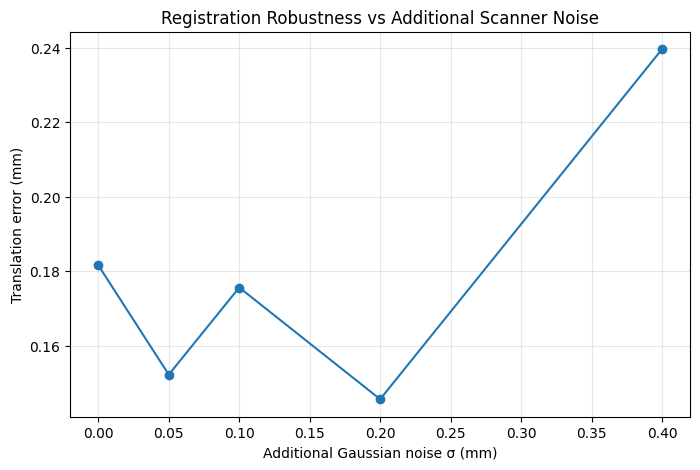

In [62]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    df["additional_noise_std_mm"],
    df["translation_error_mm"],
    marker="o"
)

plt.xlabel("Additional Gaussian noise σ (mm)")
plt.ylabel("Translation error (mm)")
plt.title("Registration Robustness vs Additional Scanner Noise")
plt.grid(alpha=0.3)

plt.show()

In [63]:
import numpy as np
import open3d as o3d
from pathlib import Path

DROPOUT_DIR = PROJECT_ROOT / "benchmarks/dropout_experiment"
DROPOUT_DIR.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(123)

base_points = np.asarray(raw_scan.points).copy()

dropout_levels = [0.0, 0.10, 0.25, 0.40, 0.60]

dropout_scans = []

for dropout in dropout_levels:

    keep_probability = 1.0 - dropout

    mask = rng.random(len(base_points)) < keep_probability

    remaining_points = base_points[mask]

    cloud = o3d.geometry.PointCloud()
    cloud.points = o3d.utility.Vector3dVector(remaining_points)

    path = DROPOUT_DIR / f"scan_dropout_{dropout:.2f}.ply"

    o3d.io.write_point_cloud(str(path), cloud)

    dropout_scans.append({
        "dropout_fraction": dropout,
        "path": path,
        "num_points": len(remaining_points)
    })

    print(
        f"Dropout: {dropout*100:.0f}% | "
        f"Remaining points: {len(remaining_points)}"
    )

Dropout: 0% | Remaining points: 9122
Dropout: 10% | Remaining points: 8197
Dropout: 25% | Remaining points: 6884
Dropout: 40% | Remaining points: 5447
Dropout: 60% | Remaining points: 3622


In [64]:
import pandas as pd
from scipy.spatial.transform import Rotation

dropout_results = []

for experiment in dropout_scans:

    dropout = experiment["dropout_fraction"]

    print(f"\nTesting dropout = {dropout*100:.0f}%")

    test_scan = o3d.io.read_point_cloud(
        str(experiment["path"])
    )

    try:
        _, diagnostics = registration.register_scan(
            nominal_mesh,
            test_scan,
            config
        )

        T_est = np.array(diagnostics["transformation"])

        R_delta = T_est[:3, :3] @ T_true[:3, :3].T

        rotation_error = np.degrees(
            Rotation.from_matrix(R_delta).magnitude()
        )

        translation_error = np.linalg.norm(
            T_est[:3, 3] - T_true[:3, 3]
        )

        dropout_results.append({
            "dropout_fraction": dropout,
            "remaining_points": experiment["num_points"],
            "rotation_error_deg": rotation_error,
            "translation_error_mm": translation_error,
            "fitness": diagnostics["final_fitness"],
            "rmse_mm": diagnostics["final_rmse_mm"],
            "status": "COMPLETED"
        })

        print(f"Rotation error: {rotation_error:.4f}°")
        print(f"Translation error: {translation_error:.4f} mm")

    except Exception as e:

        dropout_results.append({
            "dropout_fraction": dropout,
            "remaining_points": experiment["num_points"],
            "rotation_error_deg": np.nan,
            "translation_error_mm": np.nan,
            "fitness": np.nan,
            "rmse_mm": np.nan,
            "status": "ERROR"
        })

        print("Registration error:", str(e))


Testing dropout = 0%
[Open3D WARNING] Too few correspondences (156) after mutual filter, fall back to original correspondences.
Rotation error: 179.8939°
Translation error: 79.8431 mm

Testing dropout = 10%
[Open3D WARNING] Too few correspondences (145) after mutual filter, fall back to original correspondences.
Rotation error: 0.3500°
Translation error: 0.1413 mm

Testing dropout = 25%
[Open3D WARNING] Too few correspondences (127) after mutual filter, fall back to original correspondences.
Rotation error: 179.9411°
Translation error: 79.8192 mm

Testing dropout = 40%
[Open3D WARNING] Too few correspondences (115) after mutual filter, fall back to original correspondences.
Rotation error: 0.2848°
Translation error: 0.2427 mm

Testing dropout = 60%
[Open3D WARNING] Too few correspondences (66) after mutual filter, fall back to original correspondences.
Rotation error: 0.3096°
Translation error: 0.1579 mm


In [65]:
dropout_df = pd.DataFrame(dropout_results)

display(dropout_df.round(4))

csv_path = DROPOUT_DIR / "dropout_benchmark.csv"

dropout_df.to_csv(csv_path, index=False)

print("Saved:", csv_path)

,dropout_fraction,remaining_points,rotation_error_deg,translation_error_mm,fitness,rmse_mm,status
0,0.00,9122,179.8939,79.8431,0.9868,0.7585,COMPLETED
1,0.10,8197,0.3500,0.1413,0.9873,0.6835,COMPLETED
2,0.25,6884,179.9411,79.8192,0.9861,0.7680,COMPLETED
3,0.40,5447,0.2848,0.2427,0.9827,0.6796,COMPLETED
4,0.60,3622,0.3096,0.1579,0.9867,0.6757,COMPLETED


Saved: /content/drive/MyDrive/Scan-to-CAD_System/benchmarks/dropout_experiment/dropout_benchmark.csv


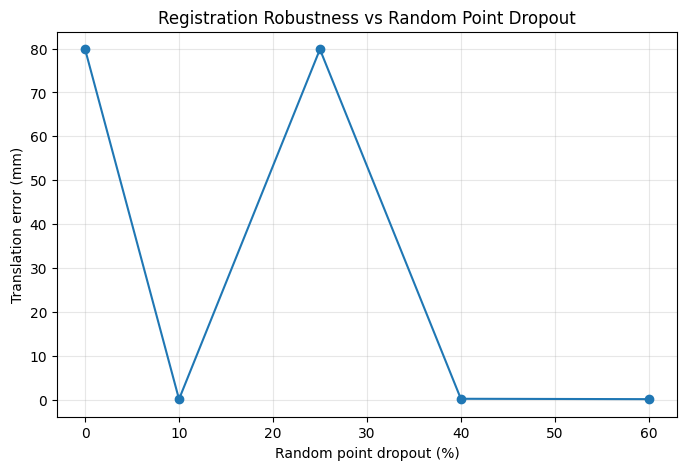

In [66]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    dropout_df["dropout_fraction"] * 100,
    dropout_df["translation_error_mm"],
    marker="o"
)

plt.xlabel("Random point dropout (%)")
plt.ylabel("Translation error (mm)")
plt.title("Registration Robustness vs Random Point Dropout")

plt.grid(alpha=0.3)
plt.show()

In [67]:
import numpy as np

def classify_pose(row):
    if row["status"] == "ERROR":
        return "ERROR"

    rot = row["rotation_error_deg"]
    trans = row["translation_error_mm"]

    if not np.isfinite(rot) or not np.isfinite(trans):
        return "ERROR"

    if rot < 2.0 and trans < 2.0:
        return "SUCCESS"

    return "POSE_FAILURE"


dropout_df["benchmark_outcome"] = dropout_df.apply(
    classify_pose,
    axis=1
)

display(dropout_df.round(4))

,dropout_fraction,remaining_points,rotation_error_deg,translation_error_mm,fitness,rmse_mm,status,benchmark_outcome
0,0.00,9122,179.8939,79.8431,0.9868,0.7585,COMPLETED,POSE_FAILURE
1,0.10,8197,0.3500,0.1413,0.9873,0.6835,COMPLETED,SUCCESS
2,0.25,6884,179.9411,79.8192,0.9861,0.7680,COMPLETED,POSE_FAILURE
3,0.40,5447,0.2848,0.2427,0.9827,0.6796,COMPLETED,SUCCESS
4,0.60,3622,0.3096,0.1579,0.9867,0.6757,COMPLETED,SUCCESS


In [68]:
import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation

same_scan_results = []

test_scan = o3d.io.read_point_cloud(
    str(dropout_scans[0]["path"])
)

for trial in range(10):

    print(f"\nTrial {trial + 1}/10")

    _, diag = registration.register_scan(
        nominal_mesh,
        test_scan,
        config
    )

    T_est = np.asarray(diag["transformation"])

    R_delta = T_est[:3, :3] @ T_true[:3, :3].T

    rot_error = np.degrees(
        Rotation.from_matrix(R_delta).magnitude()
    )

    trans_error = np.linalg.norm(
        T_est[:3, 3] - T_true[:3, 3]
    )

    success = (
        rot_error < 2.0 and
        trans_error < 2.0
    )

    same_scan_results.append({
        "trial": trial + 1,
        "rotation_error_deg": rot_error,
        "translation_error_mm": trans_error,
        "fitness": diag["final_fitness"],
        "rmse_mm": diag["final_rmse_mm"],
        "pose_success": success
    })

    print(
        f"Rotation: {rot_error:.3f}° | "
        f"Translation: {trans_error:.3f} mm | "
        f"Success: {success}"
    )

same_scan_df = pd.DataFrame(same_scan_results)

display(same_scan_df.round(4))

print(
    "\nObserved success rate:",
    100 * same_scan_df["pose_success"].mean(),
    "%"
)


Trial 1/10
[Open3D WARNING] Too few correspondences (149) after mutual filter, fall back to original correspondences.
Rotation: 0.252° | Translation: 0.235 mm | Success: True

Trial 2/10
[Open3D WARNING] Too few correspondences (162) after mutual filter, fall back to original correspondences.
Rotation: 0.276° | Translation: 0.204 mm | Success: True

Trial 3/10
[Open3D WARNING] Too few correspondences (163) after mutual filter, fall back to original correspondences.
Rotation: 0.270° | Translation: 0.161 mm | Success: True

Trial 4/10
[Open3D WARNING] Too few correspondences (155) after mutual filter, fall back to original correspondences.
Rotation: 0.245° | Translation: 0.150 mm | Success: True

Trial 5/10
[Open3D WARNING] Too few correspondences (155) after mutual filter, fall back to original correspondences.
Rotation: 0.261° | Translation: 0.184 mm | Success: True

Trial 6/10
[Open3D WARNING] Too few correspondences (160) after mutual filter, fall back to original correspondences.
R

,trial,rotation_error_deg,translation_error_mm,fitness,rmse_mm,pose_success
0,1,0.2521,0.2353,0.9868,0.6857,True
1,2,0.2759,0.2038,0.9868,0.6831,True
2,3,0.2703,0.1607,0.9868,0.6845,True
3,4,0.2452,0.1501,0.9867,0.6859,True
4,5,0.2607,0.1842,0.9867,0.6846,True
5,6,0.3084,0.1727,0.9868,0.6813,True
6,7,0.2991,0.1681,0.9868,0.6825,True
7,8,0.2644,0.1649,0.9868,0.6853,True
8,9,0.2502,0.1640,0.9867,0.6867,True
9,10,0.2849,0.1955,0.9868,0.6803,True



Observed success rate: 100.0 %


In [69]:
import numpy as np
import registration

good_transform = None
bad_transform = None

for trial in range(20):

    _, diag = registration.register_scan(
        nominal_mesh,
        test_scan,
        config
    )

    T_est = np.array(diag["transformation"])

    rot_error, trans_error = calculate_pose_error(
        T_est,
        T_true
    )

    if rot_error < 2.0 and trans_error < 2.0:
        if good_transform is None:
            good_transform = T_est.copy()
            print("Captured good transformation")

    else:
        if bad_transform is None:
            bad_transform = T_est.copy()
            print("Captured bad transformation")

    if good_transform is not None and bad_transform is not None:
        break

print("Good captured:", good_transform is not None)
print("Bad captured:", bad_transform is not None)

[Open3D WARNING] Too few correspondences (166) after mutual filter, fall back to original correspondences.
Captured good transformation
[Open3D WARNING] Too few correspondences (167) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (175) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (175) after mutual filter, fall back to original correspondences.
Captured bad transformation
Good captured: True
Bad captured: True


In [70]:
import copy

good_scan = None
bad_scan = None

if good_transform is not None:
    good_scan = copy.deepcopy(test_scan)
    good_scan.transform(good_transform)

if bad_transform is not None:
    bad_scan = copy.deepcopy(test_scan)
    bad_scan.transform(bad_transform)

In [71]:
import features

for label, scan in [
    ("GOOD REGISTRATION", good_scan),
    ("BAD REGISTRATION", bad_scan)
]:
    if scan is None:
        continue

    points = np.asarray(scan.points)

    print(f"\n{label}")

    for hole_name in ["hole_1", "hole_2"]:

        hole_cfg = config["features"][hole_name]

        result = features.measure_horizontal_hole(
            points,
            approx_y=hole_cfg["approx_center_y_mm"],
            approx_x=hole_cfg["approx_center_x_mm"]
        )

        print(f"\n{hole_name}:")
        print(result)


GOOD REGISTRATION

hole_1:
{'status': 'MEASURED', 'center_y_mm': 15.389752062298896, 'center_x_mm': 6.451529312162852, 'diameter_mm': 4.989228640893687, 'fit_rmse_mm': 0.10183824789375329, 'num_points': 81}

hole_2:
{'status': 'MEASURED', 'center_y_mm': 34.482733426482966, 'center_x_mm': 6.509273234560178, 'diameter_mm': 5.019293333801621, 'fit_rmse_mm': 0.10718686116721945, 'num_points': 89}

BAD REGISTRATION

hole_1:
{'status': 'REVIEW', 'reason': 'Insufficient candidate wall points', 'num_points': 30}

hole_2:
{'status': 'REVIEW', 'reason': 'Insufficient candidate wall points', 'num_points': 41}


In [72]:
from pathlib import Path

PIPELINE_PATH = PROJECT_ROOT / "src/run_pipeline.py"

code = PIPELINE_PATH.read_text()

feature_gate_code = '''

def check_registration_features(registered_scan, config):
    """
    Check whether expected horizontal hole features
    are observable after registration.

    Returns ACCEPTABLE or REVIEW.
    """

    import numpy as np
    from features import measure_horizontal_hole

    points = np.asarray(registered_scan.points)

    diagnostics = {}

    for hole_name in ["hole_1", "hole_2"]:

        hole_cfg = config["features"][hole_name]

        result = measure_horizontal_hole(
            points,
            approx_y=hole_cfg["approx_center_y_mm"],
            approx_x=hole_cfg["approx_center_x_mm"]
        )

        diagnostics[hole_name] = result

        if result["status"] != "MEASURED":
            return "REVIEW", diagnostics

    return "ACCEPTABLE", diagnostics
'''

if "def check_registration_features(" not in code:
    marker = "\ndef run_pipeline("

    assert marker in code, "Could not locate run_pipeline()"

    code = code.replace(
        marker,
        feature_gate_code + marker
    )

PIPELINE_PATH.write_text(code)

print("Feature-aware validation function added!")

Feature-aware validation function added!


In [73]:
import importlib
import run_pipeline

importlib.reload(run_pipeline)

for name, scan in [
    ("GOOD", good_scan),
    ("BAD", bad_scan)
]:
    status, details = (
        run_pipeline.check_registration_features(
            scan,
            config
        )
    )

    print(f"\n{name} registration")
    print("Feature validation:", status)

    for hole_name, result in details.items():
        print(
            hole_name,
            result["status"],
            result.get("num_points")
        )


GOOD registration
Feature validation: ACCEPTABLE
hole_1 ACCEPTABLE None
hole_2 ACCEPTABLE None

BAD registration
Feature validation: REVIEW
hole_1 REVIEW None
hole_2 REVIEW None


In [74]:
import importlib
import run_pipeline

importlib.reload(run_pipeline)

OUTPUT_DIR = PROJECT_ROOT / "outputs/feature_validated_test"

report = run_pipeline.run_pipeline(
    cad_path=CAD_PATH,
    scan_path=SCAN_PATH,
    config_path=CONFIG_PATH,
    output_dir=OUTPUT_DIR
)

print("Overall inspection:", report["inspection"]["overall_status"])

feature_info = report["registration"].get("feature_validation", {})

print(
    "Feature validation:",
    feature_info.get("status", "NOT RUN")
)

print(
    "Defect detection included:",
    "defect_detection" in report
)

[Open3D WARNING] Too few correspondences (153) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (169) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (166) after mutual filter, fall back to original correspondences.
Overall inspection: FAIL
Feature validation: ACCEPTABLE
Defect detection included: True


In [75]:
import numpy as np
import pandas as pd
import registration
import run_pipeline

gate_results = []

for trial in range(10):

    print(f"\nTrial {trial + 1}/10")

    aligned_scan, diag = registration.register_scan(
        nominal_mesh,
        raw_scan,
        config
    )

    # Ground-truth pose error — benchmark only
    T_est = np.asarray(diag["transformation"])

    rot_error, trans_error = calculate_pose_error(
        T_est,
        T_true
    )

    pose_correct = (
        rot_error < 2.0 and
        trans_error < 2.0
    )

    # Operational checks — no ground truth used
    basic_status = run_pipeline.check_registration(
        diag,
        config
    )

    if basic_status == "ACCEPTABLE":
        feature_status, feature_details = (
            run_pipeline.check_registration_features(
                aligned_scan,
                config
            )
        )
    else:
        feature_status = "NOT_RUN"
        feature_details = {}

    final_status = (
        "ACCEPTABLE"
        if basic_status == "ACCEPTABLE"
        and feature_status == "ACCEPTABLE"
        else "REVIEW"
    )

    gate_results.append({
        "trial": trial + 1,
        "rotation_error_deg": rot_error,
        "translation_error_mm": trans_error,
        "pose_correct": bool(pose_correct),
        "fitness": diag["final_fitness"],
        "basic_gate": basic_status,
        "feature_gate": feature_status,
        "final_gate": final_status
    })

    print(
        f"Pose correct: {pose_correct} | "
        f"Basic gate: {basic_status} | "
        f"Feature gate: {feature_status} | "
        f"Final: {final_status}"
    )


Trial 1/10
[Open3D WARNING] Too few correspondences (155) after mutual filter, fall back to original correspondences.
Pose correct: True | Basic gate: ACCEPTABLE | Feature gate: ACCEPTABLE | Final: ACCEPTABLE

Trial 2/10
[Open3D WARNING] Too few correspondences (162) after mutual filter, fall back to original correspondences.
Pose correct: True | Basic gate: ACCEPTABLE | Feature gate: ACCEPTABLE | Final: ACCEPTABLE

Trial 3/10
[Open3D WARNING] Too few correspondences (170) after mutual filter, fall back to original correspondences.
Pose correct: True | Basic gate: ACCEPTABLE | Feature gate: ACCEPTABLE | Final: ACCEPTABLE

Trial 4/10
[Open3D WARNING] Too few correspondences (157) after mutual filter, fall back to original correspondences.
Pose correct: True | Basic gate: ACCEPTABLE | Feature gate: ACCEPTABLE | Final: ACCEPTABLE

Trial 5/10
[Open3D WARNING] Too few correspondences (150) after mutual filter, fall back to original correspondences.
Pose correct: True | Basic gate: ACCEPTAB

In [76]:
gate_df = pd.DataFrame(gate_results)

false_accept = (
    (~gate_df["pose_correct"]) &
    (gate_df["final_gate"] == "ACCEPTABLE")
)

false_reject = (
    (gate_df["pose_correct"]) &
    (gate_df["final_gate"] != "ACCEPTABLE")
)

correct_accept = (
    (gate_df["pose_correct"]) &
    (gate_df["final_gate"] == "ACCEPTABLE")
)

correct_reject = (
    (~gate_df["pose_correct"]) &
    (gate_df["final_gate"] != "ACCEPTABLE")
)

print("Total trials:", len(gate_df))
print("Correct acceptances:", correct_accept.sum())
print("Correct rejections:", correct_reject.sum())
print("False acceptances:", false_accept.sum())
print("False rejections:", false_reject.sum())

display(gate_df.round(4))

Total trials: 10
Correct acceptances: 10
Correct rejections: 0
False acceptances: 0
False rejections: 0


,trial,rotation_error_deg,translation_error_mm,pose_correct,fitness,basic_gate,feature_gate,final_gate
0,1,0.2831,0.1642,True,0.9868,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE
1,2,0.2654,0.1598,True,0.9868,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE
2,3,0.2881,0.1774,True,0.9868,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE
3,4,0.2869,0.1488,True,0.9867,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE
4,5,0.2600,0.2120,True,0.9868,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE
5,6,0.2763,0.1437,True,0.9868,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE
6,7,0.2844,0.1854,True,0.9867,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE
7,8,0.2916,0.1442,True,0.9867,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE
8,9,0.2541,0.1839,True,0.9868,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE
9,10,0.2803,0.1425,True,0.9868,ACCEPTABLE,ACCEPTABLE,ACCEPTABLE


In [77]:
incorrect_count = (~gate_df["pose_correct"]).sum()
correct_count = gate_df["pose_correct"].sum()

false_accept_rate = (
    false_accept.sum() / incorrect_count
    if incorrect_count > 0 else np.nan
)

false_reject_rate = (
    false_reject.sum() / correct_count
    if correct_count > 0 else np.nan
)

print(
    "False acceptance rate:",
    f"{false_accept_rate:.1%}"
    if np.isfinite(false_accept_rate)
    else "N/A — no incorrect poses"
)

print(
    "False rejection rate:",
    f"{false_reject_rate:.1%}"
    if np.isfinite(false_reject_rate)
    else "N/A — no correct poses"
)

False acceptance rate: N/A — no incorrect poses
False rejection rate: 0.0%


In [78]:
from pathlib import Path

GATE_BENCHMARK_DIR = (
    PROJECT_ROOT / "benchmarks/registration_gate"
)

GATE_BENCHMARK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

csv_path = GATE_BENCHMARK_DIR / "gate_benchmark.csv"

gate_df.to_csv(csv_path, index=False)

print("Saved:", csv_path)

Saved: /content/drive/MyDrive/Scan-to-CAD_System/benchmarks/registration_gate/gate_benchmark.csv


In [79]:
import numpy as np
import open3d as o3d

good_points = np.asarray(good_scan.points)

# Approximate Hole 1 center in CAD coordinates
hole_y = 15.5
hole_x = 6.5

radial_distance = np.sqrt(
    (good_points[:, 1] - hole_y)**2 +
    (good_points[:, 0] - hole_x)**2
)

# Remove points from Hole 1's cylindrical wall region
occlusion_mask = (
    (radial_distance < 3.5) &
    (good_points[:, 2] > 1.0) &
    (good_points[:, 2] < 3.5)
)

occluded_points = good_points[~occlusion_mask]

occluded_scan = o3d.geometry.PointCloud()
occluded_scan.points = o3d.utility.Vector3dVector(
    occluded_points
)

print("Original points:", len(good_points))
print("Occluded points:", len(occluded_points))
print("Removed points:", np.sum(occlusion_mask))

Original points: 9122
Occluded points: 9021
Removed points: 101


In [80]:
status, details = (
    run_pipeline.check_registration_features(
        occluded_scan,
        config
    )
)

print("Feature validation:", status)

for hole_name, result in details.items():
    print(
        hole_name,
        result["status"],
        result.get("num_points")
    )

Feature validation: REVIEW
hole_1 REVIEW None
hole_2 ACCEPTABLE None


In [81]:
for name, scan in [
    ("Original correct registration", good_scan),
    ("Correct registration with occlusion", occluded_scan)
]:
    status, details = (
        run_pipeline.check_registration_features(
            scan,
            config
        )
    )

    print(f"\n{name}")
    print("Status:", status)

    for hole_name, result in details.items():
        print(
            hole_name,
            "Points:", result.get("num_points"),
            "Status:", result["status"]
        )


Original correct registration
Status: ACCEPTABLE
hole_1 Points: None Status: ACCEPTABLE
hole_2 Points: None Status: ACCEPTABLE

Correct registration with occlusion
Status: REVIEW
hole_1 Points: None Status: REVIEW
hole_2 Points: None Status: ACCEPTABLE


In [82]:
import importlib
import run_pipeline

importlib.reload(run_pipeline)

print("Updated function loaded!")

Updated function loaded!


In [83]:
for name, scan in [
    ("Original correct registration", good_scan),
    ("Correct registration with occlusion", occluded_scan)
]:
    status, details = (
        run_pipeline.check_registration_features(
            scan,
            config
        )
    )

    print(f"\n{name}")
    print("Overall status:", status)

    for hole_name, result in details.items():
        print(
            hole_name,
            "| Status:", result["status"],
            "| Points:", result["points_observed"],
            "| Reason:", result.get("reason", "None")
        )


Original correct registration
Overall status: ACCEPTABLE
hole_1 | Status: ACCEPTABLE | Points: 81 | Reason: None
hole_2 | Status: ACCEPTABLE | Points: 89 | Reason: None

Correct registration with occlusion
Overall status: REVIEW
hole_1 | Status: REVIEW | Points: 0 | Reason: Insufficient candidate wall points
hole_2 | Status: ACCEPTABLE | Points: 89 | Reason: None


In [84]:
coverage_code = '''

def calculate_hole_angular_coverage(
    points,
    center_y,
    center_x,
    num_sectors=36
):
    """
    Calculate angular coverage around a hole center.

    Assumes points belong to the cylindrical wall.
    Returns the fraction of occupied angular sectors.
    """

    import numpy as np

    points = np.asarray(points, dtype=float)

    if len(points) == 0:
        return {
            "coverage_percent": 0.0,
            "occupied_sectors": 0,
            "total_sectors": num_sectors
        }

    angles = np.arctan2(
        points[:, 0] - center_y,
        points[:, 1] - center_x
    )

    angles = np.mod(angles, 2 * np.pi)

    sector_indices = np.floor(
        angles / (2 * np.pi) * num_sectors
    ).astype(int)

    sector_indices = np.clip(
        sector_indices, 0, num_sectors - 1
    )

    occupied = len(np.unique(sector_indices))

    return {
        "coverage_percent": float(
            100 * occupied / num_sectors
        ),
        "occupied_sectors": int(occupied),
        "total_sectors": int(num_sectors)
    }
'''

FEATURES_PATH = PROJECT_ROOT / "src/features.py"

code = FEATURES_PATH.read_text()

if "def calculate_hole_angular_coverage(" not in code:
    with open(FEATURES_PATH, "a") as f:
        f.write(coverage_code)

print("Angular coverage function saved!")

Angular coverage function saved!


In [85]:
import importlib
import features

importlib.reload(features)

print("Updated features module loaded!")

Updated features module loaded!


In [86]:
import numpy as np

points = np.asarray(good_scan.points)

hole_cfg = config["features"]["hole_1"]

approx_y = hole_cfg["approx_center_y_mm"]
approx_x = hole_cfg["approx_center_x_mm"]

radial = np.sqrt(
    (points[:, 1] - approx_y)**2 +
    (points[:, 0] - approx_x)**2
)

wall_mask = (
    (radial < 3.5) &
    (points[:, 2] > 1.2) &
    (points[:, 2] < 3.2)
)

hole_wall_points = points[wall_mask]

print("Hole 1 wall points:", len(hole_wall_points))

Hole 1 wall points: 81


In [87]:
hole_result = features.measure_horizontal_hole(
    points,
    approx_y=approx_y,
    approx_x=approx_x
)

print("Hole measurement status:", hole_result["status"])

if hole_result["status"] == "MEASURED":

    coverage = features.calculate_hole_angular_coverage(
        hole_wall_points[:, [1, 0]],
        center_y=hole_result["center_y_mm"],
        center_x=hole_result["center_x_mm"]
    )

    print("Angular coverage:", coverage)

Hole measurement status: MEASURED
Angular coverage: {'coverage_percent': 100.0, 'occupied_sectors': 36, 'total_sectors': 36}


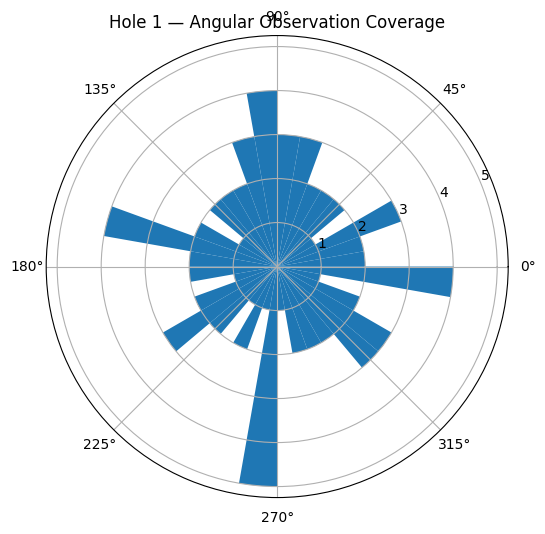

In [88]:
import matplotlib.pyplot as plt

if hole_result["status"] == "MEASURED":

    cy = hole_result["center_y_mm"]
    cx = hole_result["center_x_mm"]

    angles = np.mod(
        np.arctan2(
            hole_wall_points[:, 0] - cx,
            hole_wall_points[:, 1] - cy
        ),
        2 * np.pi
    )

    fig, ax = plt.subplots(
        figsize=(6, 6),
        subplot_kw={"projection": "polar"}
    )

    ax.hist(
        angles,
        bins=36,
        range=(0, 2*np.pi)
    )

    ax.set_title(
        "Hole 1 — Angular Observation Coverage"
    )

    plt.show()

In [89]:
import numpy as np
import open3d as o3d

good_points = np.asarray(good_scan.points)

hole_cfg = config["features"]["hole_1"]

approx_y = hole_cfg["approx_center_y_mm"]
approx_x = hole_cfg["approx_center_x_mm"]

# Locate the same cylindrical-wall region
radial = np.sqrt(
    (good_points[:, 1] - approx_y)**2 +
    (good_points[:, 0] - approx_x)**2
)

wall_region = (
    (radial < 3.5) &
    (good_points[:, 2] > 1.2) &
    (good_points[:, 2] < 3.2)
)

# Angle around the hole
angles = np.mod(
    np.arctan2(
        good_points[:, 0] - approx_x,
        good_points[:, 1] - approx_y
    ),
    2 * np.pi
)

# Remove wall observations from half the circumference
remove_mask = (
    wall_region &
    (angles >= 0) &
    (angles < np.pi)
)

partial_points = good_points[~remove_mask]

partial_scan = o3d.geometry.PointCloud()
partial_scan.points = o3d.utility.Vector3dVector(
    partial_points
)

print("Original scan points:", len(good_points))
print("Partial scan points:", len(partial_points))
print("Removed wall points:", np.sum(remove_mask))

Original scan points: 9122
Partial scan points: 9080
Removed wall points: 42


In [90]:
partial_result = features.measure_horizontal_hole(
    partial_points,
    approx_y=approx_y,
    approx_x=approx_x
)

print("Partial hole measurement:")
print(partial_result)

Partial hole measurement:
{'status': 'REVIEW', 'reason': 'Insufficient candidate wall points', 'num_points': 39}


In [91]:
radial_partial = np.sqrt(
    (partial_points[:, 1] - approx_y)**2 +
    (partial_points[:, 0] - approx_x)**2
)

partial_wall_mask = (
    (radial_partial < 3.5) &
    (partial_points[:, 2] > 1.2) &
    (partial_points[:, 2] < 3.2)
)

partial_wall_points = partial_points[partial_wall_mask]

# Use the original fitted center as a stable reference
original_hole = features.measure_horizontal_hole(
    good_points,
    approx_y=approx_y,
    approx_x=approx_x
)

coverage_partial = features.calculate_hole_angular_coverage(
    partial_wall_points[:, [1, 0]],
    center_y=original_hole["center_y_mm"],
    center_x=original_hole["center_x_mm"]
)

print("Remaining wall points:", len(partial_wall_points))
print("Partial angular coverage:", coverage_partial)

Remaining wall points: 39
Partial angular coverage: {'coverage_percent': 50.0, 'occupied_sectors': 18, 'total_sectors': 36}


In [92]:
print("FULL HOLE")
print("Wall points:", len(hole_wall_points))
print("Angular coverage:", coverage["coverage_percent"], "%")

print("\nPARTIALLY OCCLUDED HOLE")
print("Wall points:", len(partial_wall_points))
print(
    "Angular coverage:",
    coverage_partial["coverage_percent"],
    "%"
)

print("\nMeasurement status:", partial_result["status"])

FULL HOLE
Wall points: 81
Angular coverage: 100.0 %

PARTIALLY OCCLUDED HOLE
Wall points: 39
Angular coverage: 50.0 %

Measurement status: REVIEW


In [93]:
import numpy as np

rng = np.random.default_rng(42)

# Existing partial wall observations
original_partial_wall = partial_wall_points.copy()

# Create additional points near existing observations
extra_points = original_partial_wall + rng.normal(
    loc=0.0,
    scale=0.01,
    size=original_partial_wall.shape
)

# Combine original and additional observations
dense_partial_wall = np.vstack([
    original_partial_wall,
    extra_points
])

print("Total wall points:", len(dense_partial_wall))

Total wall points: 78


In [94]:
dense_coverage = features.calculate_hole_angular_coverage(
    dense_partial_wall[:, [1, 0]],
    center_y=original_hole["center_y_mm"],
    center_x=original_hole["center_x_mm"]
)

print("Dense partial-hole coverage:")
print(dense_coverage)

Dense partial-hole coverage:
{'coverage_percent': 50.0, 'occupied_sectors': 18, 'total_sectors': 36}


In [95]:
MIN_POINTS = 50
MIN_ANGULAR_COVERAGE = 70.0

point_count_pass = len(dense_partial_wall) >= MIN_POINTS

coverage_pass = (
    dense_coverage["coverage_percent"]
    >= MIN_ANGULAR_COVERAGE
)

print("Point-count check:", "PASS" if point_count_pass else "REVIEW")
print("Angular-coverage check:", "PASS" if coverage_pass else "REVIEW")

if point_count_pass and coverage_pass:
    final_quality = "ACCEPTABLE"
else:
    final_quality = "REVIEW"

print("Combined quality:", final_quality)

Point-count check: PASS
Angular-coverage check: REVIEW
Combined quality: REVIEW


In [96]:
from pathlib import Path
import ast

FEATURES_PATH = PROJECT_ROOT / "src/features.py"

new_function = '''
def measure_horizontal_hole(
    points,
    approx_y,
    approx_x,
    search_radius=3.5,
    z_min=1.2,
    z_max=3.2,
    nominal_radius=2.5,
    min_points=50,
    max_rmse=0.20,
    min_coverage_percent=70.0,
    num_sectors=36
):
    """
    Guided cylindrical-hole measurement.

    Checks point count, fitting quality,
    angular coverage, and parameter bounds.
    """

    import numpy as np
    from scipy.optimize import least_squares

    points = np.asarray(points, dtype=float)

    radial = np.sqrt(
        (points[:, 1] - approx_y)**2 +
        (points[:, 0] - approx_x)**2
    )

    mask = (
        (radial < search_radius) &
        (points[:, 2] > z_min) &
        (points[:, 2] < z_max)
    )

    wall_points = points[mask]
    n = len(wall_points)

    if n < min_points:
        return {
            "status": "REVIEW",
            "reason": "Insufficient candidate wall points",
            "num_points": int(n)
        }

    xy = wall_points[:, [1, 0]]

    def residuals(params):
        cy, cx, radius = params

        return np.sqrt(
            (xy[:, 0] - cy)**2 +
            (xy[:, 1] - cx)**2
        ) - radius

    lower = np.array([
        approx_y - 1.0,
        approx_x - 1.0,
        2.0
    ])

    upper = np.array([
        approx_y + 1.0,
        approx_x + 1.0,
        3.0
    ])

    fit = least_squares(
        residuals,
        x0=[approx_y, approx_x, nominal_radius],
        bounds=(lower, upper)
    )

    cy, cx, radius = fit.x

    rmse = float(np.sqrt(np.mean(fit.fun**2)))

    # Angular coverage around fitted center
    angles = np.mod(
        np.arctan2(
            xy[:, 1] - cx,
            xy[:, 0] - cy
        ),
        2 * np.pi
    )

    sectors = np.floor(
        angles / (2 * np.pi) * num_sectors
    ).astype(int) % num_sectors

    occupied = np.zeros(num_sectors, dtype=bool)
    occupied[sectors] = True

    occupied_count = int(occupied.sum())

    coverage_percent = (
        100.0 * occupied_count / num_sectors
    )

    # Largest consecutive sequence of empty sectors,
    # including across the 0/360-degree boundary
    if occupied_count == 0:
        largest_gap_sectors = num_sectors
    elif occupied_count == num_sectors:
        largest_gap_sectors = 0
    else:
        doubled = np.concatenate([
            occupied, occupied
        ])

        current_gap = 0
        largest_gap_sectors = 0

        for observed in doubled:
            if not observed:
                current_gap += 1
                largest_gap_sectors = max(
                    largest_gap_sectors,
                    current_gap
                )
            else:
                current_gap = 0

        largest_gap_sectors = min(
            largest_gap_sectors,
            num_sectors
        )

    largest_gap_deg = (
        360.0 * largest_gap_sectors / num_sectors
    )

    result = {
        "status": "MEASURED",
        "center_y_mm": float(cy),
        "center_x_mm": float(cx),
        "diameter_mm": float(2 * radius),
        "fit_rmse_mm": rmse,
        "num_points": int(n),
        "angular_coverage_percent": float(
            coverage_percent
        ),
        "occupied_sectors": occupied_count,
        "total_sectors": int(num_sectors),
        "largest_empty_sector_gap_deg": float(
            largest_gap_deg
        )
    }

    if not fit.success or not np.isfinite(rmse):
        result["status"] = "REVIEW"
        result["reason"] = "Circle fitting failed"

    elif np.any(fit.x - lower < 0.01) or np.any(
        upper - fit.x < 0.01
    ):
        result["status"] = "REVIEW"
        result["reason"] = "Circle fit reached parameter bounds"

    elif rmse > max_rmse:
        result["status"] = "REVIEW"
        result["reason"] = "Poor circle-fitting quality"

    elif coverage_percent < min_coverage_percent:
        result["status"] = "REVIEW"
        result["reason"] = "Insufficient angular coverage"

    return result
'''

code = FEATURES_PATH.read_text()
tree = ast.parse(code)

old_function = next(
    node for node in tree.body
    if isinstance(node, ast.FunctionDef)
    and node.name == "measure_horizontal_hole"
)

lines = code.splitlines(keepends=True)

updated_code = "".join(
    lines[:old_function.lineno - 1]
    + [new_function.strip() + "\n\n"]
    + lines[old_function.end_lineno:]
)

compile(updated_code, str(FEATURES_PATH), "exec")
FEATURES_PATH.write_text(updated_code)

print("Hole measurement function updated!")

Hole measurement function updated!


In [97]:
import importlib
import features
import run_pipeline

importlib.reload(features)
importlib.reload(run_pipeline)

print("Updated modules loaded!")

Updated modules loaded!


In [98]:
for name, scan in [
    ("FULL HOLE", good_scan),
    ("PARTIALLY OCCLUDED HOLE", partial_scan)
]:
    points = np.asarray(scan.points)

    result = features.measure_horizontal_hole(
        points,
        approx_y=15.5,
        approx_x=6.5
    )

    print(f"\n{name}")
    print("Status:", result["status"])
    print("Points:", result["num_points"])
    print(
        "Angular coverage:",
        result.get("angular_coverage_percent", "N/A")
    )
    print(
        "Largest empty gap:",
        result.get("largest_empty_sector_gap_deg", "N/A")
    )
    print("Reason:", result.get("reason", "None"))


FULL HOLE
Status: MEASURED
Points: 81
Angular coverage: 100.0
Largest empty gap: 0.0
Reason: None

PARTIALLY OCCLUDED HOLE
Status: REVIEW
Points: 39
Angular coverage: N/A
Largest empty gap: N/A
Reason: Insufficient candidate wall points


In [99]:
dense_result = features.measure_horizontal_hole(
    dense_partial_wall,
    approx_y=15.5,
    approx_x=6.5
)

print("Dense partial-hole result:")

for key, value in dense_result.items():
    print(f"{key}: {value}")

Dense partial-hole result:
status: REVIEW
center_y_mm: 15.381131075141083
center_x_mm: 6.449383394709335
diameter_mm: 4.983135579094189
fit_rmse_mm: 0.09370236267175122
num_points: 78
angular_coverage_percent: 50.0
occupied_sectors: 18
total_sectors: 36
largest_empty_sector_gap_deg: 180.0
reason: Insufficient angular coverage


In [100]:
import importlib
import json
import features

importlib.reload(features)

measurements = features.measure_features(
    nominal_mesh,
    registered_scan,
    config
)

for hole_name, hole_data in measurements["holes"].items():

    measured = hole_data["measured"]

    print(f"\n{hole_name}")
    print("Status:", measured["status"])
    print("Diameter:", measured.get("diameter_mm"))
    print("Points:", measured.get("num_points"))
    print(
        "Angular coverage:",
        measured.get("angular_coverage_percent")
    )
    print(
        "Largest empty gap:",
        measured.get("largest_empty_sector_gap_deg")
    )


hole_1
Status: MEASURED
Diameter: 4.989188160890564
Points: 81
Angular coverage: 100.0
Largest empty gap: 0.0

hole_2
Status: MEASURED
Diameter: 5.0192662453535215
Points: 89
Angular coverage: 100.0
Largest empty gap: 0.0


In [101]:
import importlib
import run_pipeline

importlib.reload(run_pipeline)

OUTPUT_DIR = (
    PROJECT_ROOT /
    "outputs/coverage_validated_pipeline"
)

report = run_pipeline.run_pipeline(
    cad_path=CAD_PATH,
    scan_path=SCAN_PATH,
    config_path=CONFIG_PATH,
    output_dir=OUTPUT_DIR
)

print("Overall inspection:",
      report["inspection"]["overall_status"])

print("Feature validation:",
      report["registration"].get(
          "feature_validation", {}
      ).get("status", "NOT RUN"))

print("Defect detection included:",
      "defect_detection" in report)

[Open3D WARNING] Too few correspondences (174) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (156) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (167) after mutual filter, fall back to original correspondences.
Overall inspection: FAIL
Feature validation: ACCEPTABLE
Defect detection included: True


In [102]:
report_path = OUTPUT_DIR / "inspection_report.json"

with open(report_path, "r") as f:
    saved_report = json.load(f)

if saved_report["inspection"]["overall_status"] == "REVIEW":
    print("Inspection requires review.")
    print(saved_report["inspection"].get("reason"))

else:
    for name, data in saved_report["measurements"]["holes"].items():

        measured = data["measured"]

        print(f"\n{name}")
        print("Diameter:", measured.get("diameter_mm"))
        print(
            "Angular coverage:",
            measured.get("angular_coverage_percent")
        )
        print(
            "Largest empty gap:",
            measured.get("largest_empty_sector_gap_deg")
        )


hole_1
Diameter: 4.990283505134497
Angular coverage: 97.22222222222223
Largest empty gap: 10.0

hole_2
Diameter: 5.008413162383222
Angular coverage: 100.0
Largest empty gap: 0.0


In [103]:
import numpy as np
import pandas as pd
import open3d as o3d
from pathlib import Path

UNCERTAINTY_DIR = (
    PROJECT_ROOT / "benchmarks/measurement_repeatability"
)

UNCERTAINTY_DIR.mkdir(
    parents=True,
    exist_ok=True
)

rng = np.random.default_rng(2026)

NUM_TRIALS = 20
ADDITIONAL_NOISE_STD = 0.10  # mm

base_points = np.asarray(raw_scan.points).copy()

# Use a previously verified good transformation.
# This is for the controlled benchmark only.
assert good_transform is not None

T_fixed = np.asarray(good_transform, dtype=float)

assert T_fixed.shape == (4, 4)
assert np.all(np.isfinite(T_fixed))

print("Number of trials:", NUM_TRIALS)
print("Additional noise:", ADDITIONAL_NOISE_STD, "mm")

Number of trials: 20
Additional noise: 0.1 mm


In [104]:
import features

repeatability_results = []

for trial in range(NUM_TRIALS):

    noise = rng.normal(
        loc=0.0,
        scale=ADDITIONAL_NOISE_STD,
        size=base_points.shape
    )

    noisy_points = base_points + noise

    # Transform into the nominal CAD frame
    homogeneous = np.column_stack([
        noisy_points,
        np.ones(len(noisy_points))
    ])

    aligned_points = (
        T_fixed @ homogeneous.T
    ).T[:, :3]

    for hole_name in ["hole_1", "hole_2"]:

        hole_cfg = config["features"][hole_name]

        result = features.measure_horizontal_hole(
            aligned_points,
            approx_y=hole_cfg["approx_center_y_mm"],
            approx_x=hole_cfg["approx_center_x_mm"]
        )

        repeatability_results.append({
            "trial": trial + 1,
            "hole": hole_name,
            "status": result["status"],
            "diameter_mm": result.get("diameter_mm"),
            "center_y_mm": result.get("center_y_mm"),
            "center_x_mm": result.get("center_x_mm"),
            "fit_rmse_mm": result.get("fit_rmse_mm"),
            "angular_coverage_percent": result.get(
                "angular_coverage_percent"
            ),
            "num_points": result.get("num_points")
        })

repeatability_df = pd.DataFrame(repeatability_results)

display(repeatability_df.head(10))

,trial,hole,status,diameter_mm,center_y_mm,center_x_mm,fit_rmse_mm,angular_coverage_percent,num_points
0,1,hole_1,MEASURED,4.983031,15.367127,6.446753,0.128017,100.000000,82
1,1,hole_2,MEASURED,5.058790,34.475993,6.498062,0.127961,91.666667,82
2,2,hole_1,MEASURED,4.988344,15.398075,6.457718,0.132143,97.222222,78
3,2,hole_2,MEASURED,5.034852,34.469173,6.505064,0.136419,94.444444,87
4,3,hole_1,MEASURED,5.013393,15.378954,6.426270,0.145800,97.222222,83
5,3,hole_2,MEASURED,5.024160,34.513548,6.522973,0.148978,94.444444,91
6,4,hole_1,MEASURED,5.010866,15.379958,6.455846,0.150992,100.000000,81
7,4,hole_2,MEASURED,5.023118,34.494172,6.524507,0.154951,97.222222,87
8,5,hole_1,MEASURED,5.013467,15.411270,6.477141,0.143815,97.222222,77
9,5,hole_2,MEASURED,5.025352,34.498776,6.529853,0.161953,91.666667,91


In [105]:
summary_rows = []

for hole_name in ["hole_1", "hole_2"]:

    subset = repeatability_df[
        repeatability_df["hole"] == hole_name
    ]

    valid = subset[
        subset["status"] == "MEASURED"
    ]

    diameters = valid["diameter_mm"].dropna()

    summary_rows.append({
        "hole": hole_name,
        "trials": len(subset),
        "successful_measurements": len(diameters),
        "review_count": int(
            (subset["status"] == "REVIEW").sum()
        ),
        "mean_diameter_mm": (
            diameters.mean() if len(diameters) else np.nan
        ),
        "std_diameter_mm": (
            diameters.std(ddof=1)
            if len(diameters) > 1 else np.nan
        ),
        "min_diameter_mm": (
            diameters.min() if len(diameters) else np.nan
        ),
        "max_diameter_mm": (
            diameters.max() if len(diameters) else np.nan
        )
    })

repeatability_summary = pd.DataFrame(summary_rows)

display(repeatability_summary.round(5))

,hole,trials,successful_measurements,review_count,mean_diameter_mm,std_diameter_mm,min_diameter_mm,max_diameter_mm
0,hole_1,20,20,0,4.99725,0.01361,4.97326,5.01354
1,hole_2,20,20,0,5.01928,0.02021,4.98537,5.06263


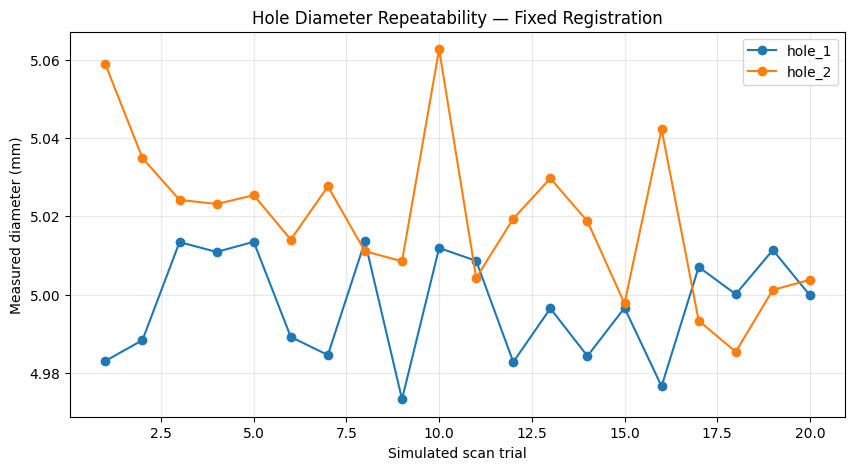

In [106]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

for hole_name in ["hole_1", "hole_2"]:

    subset = repeatability_df[
        (repeatability_df["hole"] == hole_name) &
        (repeatability_df["status"] == "MEASURED")
    ]

    plt.plot(
        subset["trial"],
        subset["diameter_mm"],
        marker="o",
        label=hole_name
    )

plt.xlabel("Simulated scan trial")
plt.ylabel("Measured diameter (mm)")
plt.title("Hole Diameter Repeatability — Fixed Registration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [107]:
repeatability_df.to_csv(
    UNCERTAINTY_DIR / "repeatability_trials.csv",
    index=False
)

repeatability_summary.to_csv(
    UNCERTAINTY_DIR / "repeatability_summary.csv",
    index=False
)

print("Repeatability benchmark saved!")

Repeatability benchmark saved!


In [108]:
import numpy as np

nominal_sample = nominal_mesh.sample_points_poisson_disk(
    number_of_points=30000
)

nominal_points = np.asarray(nominal_sample.points)

nominal_diameters = {}

for hole_name in ["hole_1", "hole_2"]:

    hole_cfg = config["features"][hole_name]

    result = features.measure_horizontal_hole(
        nominal_points,
        approx_y=hole_cfg["approx_center_y_mm"],
        approx_x=hole_cfg["approx_center_x_mm"]
    )

    if result["status"] != "MEASURED":
        raise RuntimeError(
            f"Nominal measurement failed for {hole_name}"
        )

    nominal_diameters[hole_name] = result["diameter_mm"]

    print(
        hole_name,
        "Nominal diameter:",
        result["diameter_mm"]
    )

hole_1 Nominal diameter: 4.984121810261677
hole_2 Nominal diameter: 4.983700573605396


In [109]:
bias_results = []

for _, row in repeatability_summary.iterrows():

    hole_name = row["hole"]

    nominal = nominal_diameters[hole_name]
    measured_mean = row["mean_diameter_mm"]

    bias = measured_mean - nominal

    bias_results.append({
        "hole": hole_name,
        "reference_diameter_mm": nominal,
        "mean_measured_diameter_mm": measured_mean,
        "bias_mm": bias,
        "repeatability_std_mm": row["std_diameter_mm"]
    })

bias_df = pd.DataFrame(bias_results)

display(bias_df.round(5))

,hole,reference_diameter_mm,mean_measured_diameter_mm,bias_mm,repeatability_std_mm
0,hole_1,4.98412,4.99725,0.01313,0.01361
1,hole_2,4.98370,5.01928,0.03558,0.02021


In [110]:
bias_df["two_std_repeatability_mm"] = (
    2 * bias_df["repeatability_std_mm"]
)

display(bias_df.round(5))

,hole,reference_diameter_mm,mean_measured_diameter_mm,bias_mm,repeatability_std_mm,two_std_repeatability_mm
0,hole_1,4.98412,4.99725,0.01313,0.01361,0.02721
1,hole_2,4.98370,5.01928,0.03558,0.02021,0.04041


In [111]:
import numpy as np
import pandas as pd
import registration
import features
import run_pipeline

full_repeatability = []

NUM_TRIALS = 10

for trial in range(NUM_TRIALS):

    print(f"\nTrial {trial + 1}/{NUM_TRIALS}")

    aligned_scan, diag = registration.register_scan(
        nominal_mesh,
        raw_scan,
        config
    )

    # Operational validation: no ground truth used
    basic_status = run_pipeline.check_registration(
        diag,
        config
    )

    if basic_status == "ACCEPTABLE":
        feature_status, _ = (
            run_pipeline.check_registration_features(
                aligned_scan,
                config
            )
        )
    else:
        feature_status = "NOT_RUN"

    gate_status = (
        "ACCEPTABLE"
        if basic_status == "ACCEPTABLE"
        and feature_status == "ACCEPTABLE"
        else "REVIEW"
    )

    # Ground truth is used ONLY for benchmarking
    T_est = np.asarray(diag["transformation"])

    rot_error, trans_error = calculate_pose_error(
        T_est,
        T_true
    )

    pose_correct = (
        rot_error < 2.0
        and trans_error < 2.0
    )

    row = {
        "trial": trial + 1,
        "registration_status": gate_status,
        "pose_correct": bool(pose_correct),
        "rotation_error_deg": rot_error,
        "translation_error_mm": trans_error,
        "hole_1_diameter_mm": np.nan,
        "hole_2_diameter_mm": np.nan
    }

    if gate_status == "ACCEPTABLE":
        points = np.asarray(aligned_scan.points)

        for hole_name in ["hole_1", "hole_2"]:

            cfg = config["features"][hole_name]

            result = features.measure_horizontal_hole(
                points,
                approx_y=cfg["approx_center_y_mm"],
                approx_x=cfg["approx_center_x_mm"]
            )

            if result["status"] == "MEASURED":
                row[f"{hole_name}_diameter_mm"] = (
                    result["diameter_mm"]
                )

    full_repeatability.append(row)

    print(
        f"Gate: {gate_status} | "
        f"Pose correct: {pose_correct}"
    )

full_repeatability_df = pd.DataFrame(full_repeatability)

display(full_repeatability_df.round(5))


Trial 1/10
[Open3D WARNING] Too few correspondences (162) after mutual filter, fall back to original correspondences.
Gate: REVIEW | Pose correct: False

Trial 2/10
[Open3D WARNING] Too few correspondences (163) after mutual filter, fall back to original correspondences.
Gate: REVIEW | Pose correct: False

Trial 3/10
[Open3D WARNING] Too few correspondences (154) after mutual filter, fall back to original correspondences.
Gate: ACCEPTABLE | Pose correct: True

Trial 4/10
[Open3D WARNING] Too few correspondences (163) after mutual filter, fall back to original correspondences.
Gate: ACCEPTABLE | Pose correct: True

Trial 5/10
[Open3D WARNING] Too few correspondences (168) after mutual filter, fall back to original correspondences.
Gate: REVIEW | Pose correct: False

Trial 6/10
[Open3D WARNING] Too few correspondences (161) after mutual filter, fall back to original correspondences.
Gate: ACCEPTABLE | Pose correct: True

Trial 7/10
[Open3D WARNING] Too few correspondences (163) after mu

,trial,registration_status,pose_correct,rotation_error_deg,translation_error_mm,hole_1_diameter_mm,hole_2_diameter_mm
0,1,REVIEW,False,179.95801,79.80880,NaN,NaN
1,2,REVIEW,False,179.93011,79.76415,NaN,NaN
2,3,ACCEPTABLE,True,0.26228,0.16360,4.98918,5.01931
3,4,ACCEPTABLE,True,0.24558,0.14986,4.99024,5.01587
4,5,REVIEW,False,179.91126,79.79614,NaN,NaN
5,6,ACCEPTABLE,True,0.27646,0.18464,4.98916,5.01283
6,7,ACCEPTABLE,True,0.26838,0.23049,4.99027,5.01280
7,8,ACCEPTABLE,True,0.28433,0.26217,4.98924,5.01591
8,9,REVIEW,False,179.93762,79.83329,NaN,NaN
9,10,ACCEPTABLE,True,0.27364,0.17883,4.98923,5.01281


In [112]:
accepted = full_repeatability_df[
    full_repeatability_df["registration_status"] == "ACCEPTABLE"
]

print("Total trials:", len(full_repeatability_df))
print("Accepted registrations:", len(accepted))
print(
    "Reviewed registrations:",
    (full_repeatability_df["registration_status"] == "REVIEW").sum()
)

for hole_name in ["hole_1", "hole_2"]:

    values = accepted[
        f"{hole_name}_diameter_mm"
    ].dropna()

    print(f"\n{hole_name}")
    print("Valid measurements:", len(values))

    if len(values) > 1:
        print(f"Mean diameter: {values.mean():.5f} mm")
        print(f"Standard deviation: {values.std(ddof=1):.5f} mm")
        print(f"Range: {values.max() - values.min():.5f} mm")
    else:
        print("Insufficient measurements for variability estimate")

Total trials: 10
Accepted registrations: 6
Reviewed registrations: 4

hole_1
Valid measurements: 6
Mean diameter: 4.98955 mm
Standard deviation: 0.00055 mm
Range: 0.00112 mm

hole_2
Valid measurements: 6
Mean diameter: 5.01492 mm
Standard deviation: 0.00263 mm
Range: 0.00651 mm


In [113]:
FULL_REPEAT_DIR = (
    PROJECT_ROOT / "benchmarks/full_pipeline_repeatability"
)

FULL_REPEAT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

full_repeatability_df.to_csv(
    FULL_REPEAT_DIR / "registration_measurement_trials.csv",
    index=False
)

print("Full registration repeatability results saved!")

Full registration repeatability results saved!


In [114]:
multi_start_code = '''
import numpy as np

from registration import register_scan
from features import measure_horizontal_hole


def validate_hole_features(registered_scan, config):
    """Check both expected holes without using ground truth."""

    points = np.asarray(registered_scan.points)

    details = {}

    for hole_name in ["hole_1", "hole_2"]:
        cfg = config["features"][hole_name]

        result = measure_horizontal_hole(
            points,
            approx_y=cfg["approx_center_y_mm"],
            approx_x=cfg["approx_center_x_mm"]
        )

        details[hole_name] = result

    acceptable = all(
        result["status"] == "MEASURED"
        for result in details.values()
    )

    return acceptable, details


def register_scan_multistart(
    nominal_mesh,
    raw_scan,
    config,
    num_attempts=3
):
    """
    Try registration multiple times and retain
    the best candidate passing basic and feature checks.

    Does not use synthetic ground truth.
    """

    candidates = []
    attempts = []

    minimum_fitness = config["quality"][
        "minimum_registration_fitness"
    ]

    for attempt in range(num_attempts):

        registered_scan, diagnostics = register_scan(
            nominal_mesh,
            raw_scan,
            config
        )

        fitness = diagnostics["final_fitness"]
        rmse = diagnostics["final_rmse_mm"]

        basic_ok = (
            np.isfinite(fitness)
            and np.isfinite(rmse)
            and fitness >= minimum_fitness
            and diagnostics["stable_source_points"] >= 100
        )

        if basic_ok:
            feature_ok, feature_details = validate_hole_features(
                registered_scan,
                config
            )
        else:
            feature_ok = False
            feature_details = {}

        attempt_info = {
            "attempt": attempt + 1,
            "fitness": float(fitness),
            "rmse_mm": float(rmse),
            "basic_acceptable": bool(basic_ok),
            "feature_acceptable": bool(feature_ok)
        }

        attempts.append(attempt_info)

        if basic_ok and feature_ok:
            candidates.append({
                "scan": registered_scan,
                "diagnostics": diagnostics,
                "attempt": attempt + 1
            })

    if not candidates:
        return None, {
            "status": "REVIEW",
            "reason": "No acceptable registration candidate",
            "attempts": attempts
        }

    # Rank accepted candidates by final full-scan RMSE.
    # This is a provisional ranking rule.
    best = min(
        candidates,
        key=lambda c: c["diagnostics"]["final_rmse_mm"]
    )

    return best["scan"], {
        "status": "ACCEPTABLE",
        "selected_attempt": best["attempt"],
        "attempts": attempts,
        "registration": best["diagnostics"]
    }
'''

MULTISTART_PATH = PROJECT_ROOT / "src/registration_multistart.py"

MULTISTART_PATH.write_text(multi_start_code)

print("Saved:", MULTISTART_PATH)

Saved: /content/drive/MyDrive/Scan-to-CAD_System/src/registration_multistart.py


In [115]:
import importlib
import registration_multistart

importlib.reload(registration_multistart)

aligned_multi, multi_info = (
    registration_multistart.register_scan_multistart(
        nominal_mesh,
        raw_scan,
        config,
        num_attempts=3
    )
)

print("Multi-start status:", multi_info["status"])

for attempt in multi_info["attempts"]:
    print(attempt)

if multi_info["status"] == "ACCEPTABLE":
    T_est = np.asarray(
        multi_info["registration"]["transformation"]
    )

    rot, trans = calculate_pose_error(T_est, T_true)

    print(f"\nRotation error: {rot:.4f} degrees")
    print(f"Translation error: {trans:.4f} mm")

[Open3D WARNING] Too few correspondences (161) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (170) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (160) after mutual filter, fall back to original correspondences.
Multi-start status: ACCEPTABLE
{'attempt': 1, 'fitness': 0.9868449901337426, 'rmse_mm': 0.685735144209449, 'basic_acceptable': True, 'feature_acceptable': True}
{'attempt': 2, 'fitness': 0.9868449901337426, 'rmse_mm': 0.6852636651012248, 'basic_acceptable': True, 'feature_acceptable': True}
{'attempt': 3, 'fitness': 0.9867353650515238, 'rmse_mm': 0.6853911523281426, 'basic_acceptable': True, 'feature_acceptable': True}

Rotation error: 0.2501 degrees
Translation error: 0.2159 mm


In [116]:
import time
import numpy as np
import pandas as pd

import registration
import registration_multistart
import run_pipeline

NUM_TRIALS = 20

comparison_results = []

for method in ["single_start", "multi_start"]:

    print(f"\nTesting {method}")

    for trial in range(NUM_TRIALS):

        start = time.perf_counter()

        if method == "single_start":

            aligned, diag = registration.register_scan(
                nominal_mesh,
                raw_scan,
                config
            )

            basic_status = run_pipeline.check_registration(
                diag,
                config
            )

            if basic_status == "ACCEPTABLE":
                feature_status, _ = (
                    run_pipeline.check_registration_features(
                        aligned,
                        config
                    )
                )
            else:
                feature_status = "NOT_RUN"

            gate_status = (
                "ACCEPTABLE"
                if basic_status == "ACCEPTABLE"
                and feature_status == "ACCEPTABLE"
                else "REVIEW"
            )

            T_est = np.asarray(diag["transformation"])

        else:

            aligned, info = (
                registration_multistart.register_scan_multistart(
                    nominal_mesh,
                    raw_scan,
                    config,
                    num_attempts=3
                )
            )

            gate_status = info["status"]

            T_est = (
                np.asarray(info["registration"]["transformation"])
                if gate_status == "ACCEPTABLE"
                else None
            )

        runtime = time.perf_counter() - start

        if T_est is not None:
            rot_error, trans_error = calculate_pose_error(
                T_est,
                T_true
            )

            pose_correct = (
                rot_error < 2.0
                and trans_error < 2.0
            )
        else:
            rot_error = np.nan
            trans_error = np.nan
            pose_correct = False

        comparison_results.append({
            "method": method,
            "trial": trial + 1,
            "gate_status": gate_status,
            "pose_correct": bool(pose_correct),
            "rotation_error_deg": rot_error,
            "translation_error_mm": trans_error,
            "runtime_seconds": runtime
        })

        print(
            f"Trial {trial + 1}: "
            f"{gate_status}, "
            f"Runtime: {runtime:.2f}s"
        )

comparison_df = pd.DataFrame(comparison_results)


Testing single_start
[Open3D WARNING] Too few correspondences (163) after mutual filter, fall back to original correspondences.
Trial 1: ACCEPTABLE, Runtime: 1.83s
[Open3D WARNING] Too few correspondences (158) after mutual filter, fall back to original correspondences.
Trial 2: REVIEW, Runtime: 3.22s
[Open3D WARNING] Too few correspondences (166) after mutual filter, fall back to original correspondences.
Trial 3: ACCEPTABLE, Runtime: 2.37s
[Open3D WARNING] Too few correspondences (161) after mutual filter, fall back to original correspondences.
Trial 4: REVIEW, Runtime: 1.87s
[Open3D WARNING] Too few correspondences (173) after mutual filter, fall back to original correspondences.
Trial 5: ACCEPTABLE, Runtime: 1.75s
[Open3D WARNING] Too few correspondences (155) after mutual filter, fall back to original correspondences.
Trial 6: ACCEPTABLE, Runtime: 1.76s
[Open3D WARNING] Too few correspondences (158) after mutual filter, fall back to original correspondences.
Trial 7: ACCEPTABLE, 

In [117]:
summary = []

for method, group in comparison_df.groupby("method"):

    accepted = group["gate_status"] == "ACCEPTABLE"
    correct_accepted = accepted & group["pose_correct"]
    incorrect_accepted = accepted & ~group["pose_correct"]

    summary.append({
        "method": method,
        "trials": len(group),
        "correct_accepted": int(correct_accepted.sum()),
        "incorrect_accepted": int(incorrect_accepted.sum()),
        "review_count": int((~accepted).sum()),
        "acceptance_rate_percent": float(
            100 * accepted.mean()
        ),
        "mean_runtime_seconds": float(
            group["runtime_seconds"].mean()
        )
    })

comparison_summary = pd.DataFrame(summary)

display(comparison_summary.round(3))

,method,trials,correct_accepted,incorrect_accepted,review_count,acceptance_rate_percent,mean_runtime_seconds
0,multi_start,20,20,0,0,100.0,6.099
1,single_start,20,17,0,3,85.0,2.074


In [118]:
from pathlib import Path

BENCHMARK_DIR = (
    PROJECT_ROOT / "benchmarks/multistart_comparison"
)

BENCHMARK_DIR.mkdir(
    parents=True,
    exist_ok=True
)

comparison_df.to_csv(
    BENCHMARK_DIR / "comparison_trials.csv",
    index=False
)

comparison_summary.to_csv(
    BENCHMARK_DIR / "comparison_summary.csv",
    index=False
)

print("Benchmark saved!")

Benchmark saved!


In [119]:
import json

CONFIG_PATH = PROJECT_ROOT / "configs/inspection_config.json"

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

config["registration"]["strategy"] = "multi_start"
config["registration"]["num_attempts"] = 3

with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=2)

print("Registration strategy:",
      config["registration"]["strategy"])

print("Attempts:",
      config["registration"]["num_attempts"])

Registration strategy: multi_start
Attempts: 3


In [120]:
def check_registration(diagnostics, config):
    """Validate registration diagnostics."""

    minimum_fitness = config["quality"][
        "minimum_registration_fitness"
    ]

    fitness = diagnostics.get("final_fitness")
    rmse = diagnostics.get("final_rmse_mm")
    stable_points = diagnostics.get("stable_source_points", 0)
    transform = diagnostics.get("transformation")

    if fitness is None or rmse is None or transform is None:
        return "REVIEW"

    if not np.isfinite(fitness) or fitness < minimum_fitness:
        return "REVIEW"

    if not np.isfinite(rmse):
        return "REVIEW"

    if stable_points < 100:
        return "REVIEW"

    T = np.asarray(transform, dtype=float)

    if T.shape != (4, 4) or not np.all(np.isfinite(T)):
        return "REVIEW"

    return "ACCEPTABLE"

In [121]:
import importlib
import registration_multistart
import run_pipeline

importlib.reload(registration_multistart)
importlib.reload(run_pipeline)

<module 'run_pipeline' from '/content/drive/MyDrive/Scan-to-CAD_System/src/run_pipeline.py'>

In [122]:
OUTPUT_DIR = (
    PROJECT_ROOT /
    "outputs/multistart_pipeline"
)

report = run_pipeline.run_pipeline(
    cad_path=CAD_PATH,
    scan_path=SCAN_PATH,
    config_path=CONFIG_PATH,
    output_dir=OUTPUT_DIR
)

print("Overall inspection:",
      report["inspection"]["overall_status"])

multi = report["registration"].get("multi_start", {})

print("Multi-start status:",
      multi.get("status"))

print("Selected attempt:",
      multi.get("selected_attempt"))

print("Defect detection included:",
      "defect_detection" in report)

print("Tolerance checks:",
      len(report["inspection"]["checks"]))

[Open3D WARNING] Too few correspondences (156) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (156) after mutual filter, fall back to original correspondences.
[Open3D WARNING] Too few correspondences (174) after mutual filter, fall back to original correspondences.
Overall inspection: FAIL
Multi-start status: ACCEPTABLE
Selected attempt: 2
Defect detection included: True
Tolerance checks: 7


In [123]:
from pathlib import Path

SYNTHETIC_DIR = PROJECT_ROOT / "data/synthetic"

print("Synthetic data files:\n")

for path in sorted(SYNTHETIC_DIR.iterdir()):
    print(path.name)

Synthetic data files:

defective_bracket.stl
ground_truth.json
raw_scan.ply


In [124]:
DEFECTIVE_MESH_PATH = (
    PROJECT_ROOT / "data/synthetic/defective_bracket.stl"
)

In [125]:
import open3d as o3d
import numpy as np

if DEFECTIVE_MESH_PATH.exists():

    defective_mesh = o3d.io.read_triangle_mesh(
        str(DEFECTIVE_MESH_PATH)
    )

    print("Vertices:", len(defective_mesh.vertices))
    print("Triangles:", len(defective_mesh.triangles))

    bbox = defective_mesh.get_axis_aligned_bounding_box()

    print("Bounding-box dimensions:", bbox.get_extent())

else:
    print("Defective mesh not found.")

Vertices: 2209
Triangles: 1140
Bounding-box dimensions: [15.  49.5 49.5]


In [126]:
from pathlib import Path

print("Searching for mesh files...\n")

extensions = {".stl", ".ply", ".obj", ".off", ".step", ".stp"}

for path in PROJECT_ROOT.rglob("*"):
    if path.is_file() and path.suffix.lower() in extensions:
        print(path)

Searching for mesh files...

/content/drive/MyDrive/Scan-to-CAD_System/perfect_scan.ply
/content/drive/MyDrive/Scan-to-CAD_System/defective_bracket.stl
/content/drive/MyDrive/Scan-to-CAD_System/as_built_scan.ply
/content/drive/MyDrive/Scan-to-CAD_System/benchmarks/noise_experiment/scan_noise_0.40.ply
/content/drive/MyDrive/Scan-to-CAD_System/benchmarks/noise_experiment/scan_noise_0.05.ply
/content/drive/MyDrive/Scan-to-CAD_System/benchmarks/noise_experiment/scan_noise_0.20.ply
/content/drive/MyDrive/Scan-to-CAD_System/benchmarks/noise_experiment/scan_noise_0.00.ply
/content/drive/MyDrive/Scan-to-CAD_System/benchmarks/noise_experiment/scan_noise_0.10.ply
/content/drive/MyDrive/Scan-to-CAD_System/benchmarks/dropout_experiment/scan_dropout_0.60.ply
/content/drive/MyDrive/Scan-to-CAD_System/benchmarks/dropout_experiment/scan_dropout_0.10.ply
/content/drive/MyDrive/Scan-to-CAD_System/benchmarks/dropout_experiment/scan_dropout_0.00.ply
/content/drive/MyDrive/Scan-to-CAD_System/benchmarks/dro

In [127]:
import open3d as o3d
import numpy as np

DEFECTIVE_MESH_PATH = (
    PROJECT_ROOT / "defective_bracket.stl"
)

defective_mesh = o3d.io.read_triangle_mesh(
    str(DEFECTIVE_MESH_PATH)
)

print("Vertices:", len(defective_mesh.vertices))
print("Triangles:", len(defective_mesh.triangles))
print("Is empty:", defective_mesh.is_empty())

bbox = defective_mesh.get_axis_aligned_bounding_box()

print("Bounding-box dimensions:", bbox.get_extent())

Vertices: 2209
Triangles: 1140
Is empty: False
Bounding-box dimensions: [15.  49.5 49.5]


In [128]:
nominal_vertices = np.asarray(nominal_mesh.vertices)
defective_vertices = np.asarray(defective_mesh.vertices)

if nominal_vertices.shape != defective_vertices.shape:
    print("Vertex arrays have different shapes.")
    print("Direct vertex comparison unavailable.")

else:
    displacement = defective_vertices - nominal_vertices

    displacement_magnitude = np.linalg.norm(
        displacement,
        axis=1
    )

    print(
        "Maximum vertex displacement:",
        np.max(displacement_magnitude),
        "mm"
    )

    print(
        "Mean vertex displacement:",
        np.mean(displacement_magnitude),
        "mm"
    )

    print(
        "Moved vertices:",
        np.sum(displacement_magnitude > 1e-5)
    )

    print(
        "Maximum Z displacement:",
        np.max(displacement[:, 2]),
        "mm"
    )

Vertex arrays have different shapes.
Direct vertex comparison unavailable.


In [129]:
import shutil

DESTINATION = (
    PROJECT_ROOT /
    "data/synthetic/defective_bracket.stl"
)

DESTINATION.parent.mkdir(
    parents=True,
    exist_ok=True
)

shutil.copy2(
    DEFECTIVE_MESH_PATH,
    DESTINATION
)

print("Defective mesh copied to:")
print(DESTINATION)

Defective mesh copied to:
/content/drive/MyDrive/Scan-to-CAD_System/data/synthetic/defective_bracket.stl


In [130]:
import numpy as np
import open3d as o3d

nominal_sample = nominal_mesh.sample_points_uniformly(
    number_of_points=50000
)

defective_sample = defective_mesh.sample_points_uniformly(
    number_of_points=50000
)

nominal_pts = np.asarray(nominal_sample.points)
defective_pts = np.asarray(defective_sample.points)

print("Nominal sample:", nominal_pts.shape)
print("Defective sample:", defective_pts.shape)

Nominal sample: (50000, 3)
Defective sample: (50000, 3)


In [131]:
cad_tensor = o3d.t.geometry.TriangleMesh.from_legacy(
    nominal_mesh
)

scene = o3d.t.geometry.RaycastingScene()
scene.add_triangles(cad_tensor)

distances = scene.compute_distance(
    o3d.core.Tensor(
        defective_pts.astype(np.float32)
    )
).numpy()

print("Mean surface distance:", np.mean(distances), "mm")
print("Median surface distance:", np.median(distances), "mm")
print("95th percentile:", np.percentile(distances, 95), "mm")
print("Maximum sampled distance:", np.max(distances), "mm")

Mean surface distance: 0.33754063 mm
Median surface distance: 5.8009746e-06 mm
95th percentile: 1.9340898 mm
Maximum sampled distance: 2.8432026 mm


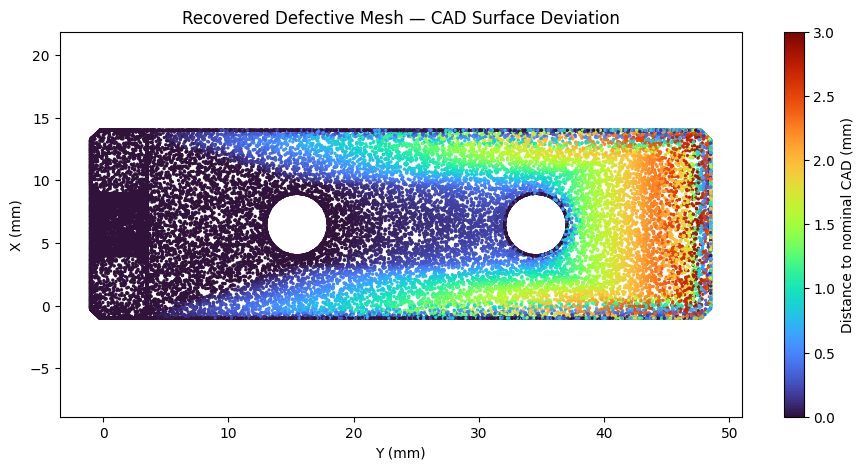

In [132]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.scatter(
    defective_pts[:, 1],
    defective_pts[:, 0],
    c=distances,
    cmap="turbo",
    s=2,
    vmin=0,
    vmax=3
)

plt.colorbar(label="Distance to nominal CAD (mm)")

plt.xlabel("Y (mm)")
plt.ylabel("X (mm)")
plt.title("Recovered Defective Mesh — CAD Surface Deviation")

plt.axis("equal")
plt.show()

In [133]:
import json

with open(GROUND_TRUTH_PATH, "r") as f:
    ground_truth = json.load(f)

T_true = np.array(
    ground_truth["scan_pose"]["scan_to_cad_transformation"]
)

import copy

scan_gt_aligned = copy.deepcopy(raw_scan)
scan_gt_aligned.transform(T_true)

PointCloud with 9122 points.

In [134]:
defective_tensor = o3d.t.geometry.TriangleMesh.from_legacy(
    defective_mesh
)

defective_scene = o3d.t.geometry.RaycastingScene()
defective_scene.add_triangles(defective_tensor)

scan_gt_pts = np.asarray(scan_gt_aligned.points)

scan_to_defective_distances = (
    defective_scene.compute_distance(
        o3d.core.Tensor(
            scan_gt_pts.astype(np.float32)
        )
    ).numpy()
)

print(
    "Median scan-to-defective distance:",
    np.median(scan_to_defective_distances),
    "mm"
)

print(
    "95th percentile:",
    np.percentile(scan_to_defective_distances, 95),
    "mm"
)

Median scan-to-defective distance: 0.06864488 mm
95th percentile: 0.20926306 mm


In [135]:
import numpy as np
import features

defective_sample = defective_mesh.sample_points_poisson_disk(
    number_of_points=50000
)

defective_points = np.asarray(defective_sample.points)

defective_holes = {}

for hole_name in ["hole_1", "hole_2"]:

    cfg = config["features"][hole_name]

    result = features.measure_horizontal_hole(
        defective_points,
        approx_y=cfg["approx_center_y_mm"],
        approx_x=cfg["approx_center_x_mm"]
    )

    defective_holes[hole_name] = result

    print(f"\n{hole_name}")
    print("Status:", result["status"])
    print("Diameter:", result.get("diameter_mm"))
    print("Center Y:", result.get("center_y_mm"))
    print("Center X:", result.get("center_x_mm"))
    print("Fit RMSE:", result.get("fit_rmse_mm"))
    print("Angular coverage:", result.get("angular_coverage_percent"))


hole_1
Status: MEASURED
Diameter: 4.983652363845109
Center Y: 15.479956295456608
Center X: 6.474165910293377
Fit RMSE: 0.003522361878831592
Angular coverage: 100.0

hole_2
Status: MEASURED
Diameter: 5.152157204488877
Center Y: 34.675037077957214
Center X: 6.474884967489608
Fit RMSE: 0.18171176852296841
Angular coverage: 100.0


In [136]:
import pandas as pd

comparison_rows = []

for hole_name in ["hole_1", "hole_2"]:

    nominal_d = nominal_diameters[hole_name]

    defective = defective_holes[hole_name]

    scan_result = (
        report["measurements"]["holes"][hole_name]["measured"]
    )

    if (
        defective["status"] != "MEASURED"
        or scan_result["status"] != "MEASURED"
    ):
        print(f"{hole_name}: REVIEW — measurement unavailable")
        continue

    defective_d = defective["diameter_mm"]
    scan_d = scan_result["diameter_mm"]

    comparison_rows.append({
        "hole": hole_name,
        "nominal_cad_mm": nominal_d,
        "defective_mesh_mm": defective_d,
        "scan_measured_mm": scan_d,
        "actual_mesh_deviation_mm": defective_d - nominal_d,
        "scan_vs_mesh_error_mm": scan_d - defective_d
    })

comparison_df = pd.DataFrame(comparison_rows)

display(comparison_df.round(5))

,hole,nominal_cad_mm,defective_mesh_mm,scan_measured_mm,actual_mesh_deviation_mm,scan_vs_mesh_error_mm
0,hole_1,4.98412,4.98365,4.98919,-0.00047,0.00553
1,hole_2,4.98370,5.15216,5.01281,0.16846,-0.13935


In [137]:
for hole_name in ["hole_1", "hole_2"]:

    defective = defective_holes[hole_name]
    scan_result = report["measurements"]["holes"][hole_name]["measured"]

    if (
        defective["status"] != "MEASURED"
        or scan_result["status"] != "MEASURED"
    ):
        continue

    dy = (
        scan_result["center_y_mm"]
        - defective["center_y_mm"]
    )

    dx = (
        scan_result["center_x_mm"]
        - defective["center_x_mm"]
    )

    center_error = np.hypot(dx, dy)

    print(f"\n{hole_name}")
    print(f"Y error: {dy:+.5f} mm")
    print(f"X error: {dx:+.5f} mm")
    print(f"2D center error: {center_error:.5f} mm")


hole_1
Y error: -0.09713 mm
X error: -0.04111 mm
2D center error: 0.10547 mm

hole_2
Y error: -0.20226 mm
X error: +0.00426 mm
2D center error: 0.20230 mm


In [138]:
import numpy as np

cfg = config["features"]["hole_2"]

approx_y = cfg["approx_center_y_mm"]
approx_x = cfg["approx_center_x_mm"]

radial = np.sqrt(
    (defective_points[:, 1] - approx_y)**2 +
    (defective_points[:, 0] - approx_x)**2
)

mask = (
    (radial < 3.5) &
    (defective_points[:, 2] > 1.2) &
    (defective_points[:, 2] < 3.2)
)

hole2_wall = defective_points[mask]

print("Selected Hole 2 points:", len(hole2_wall))

Selected Hole 2 points: 478


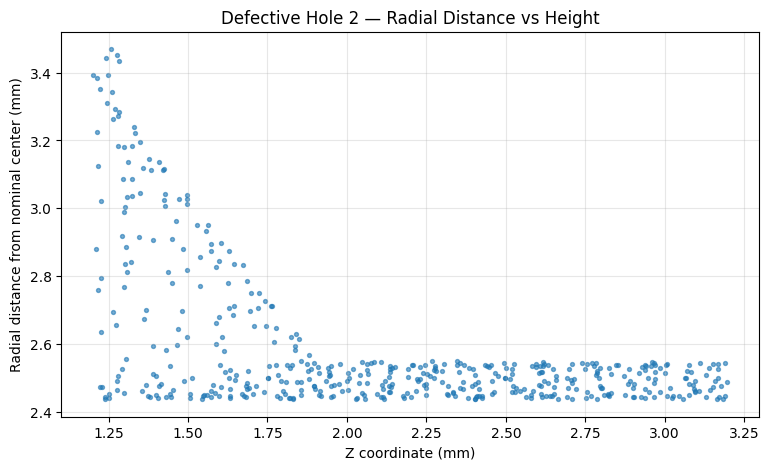

In [139]:
import matplotlib.pyplot as plt

radial_distance = np.sqrt(
    (hole2_wall[:, 1] - approx_y)**2 +
    (hole2_wall[:, 0] - approx_x)**2
)

plt.figure(figsize=(9, 5))

plt.scatter(
    hole2_wall[:, 2],
    radial_distance,
    s=8,
    alpha=0.6
)

plt.xlabel("Z coordinate (mm)")
plt.ylabel("Radial distance from nominal center (mm)")
plt.title("Defective Hole 2 — Radial Distance vs Height")
plt.grid(alpha=0.3)
plt.show()

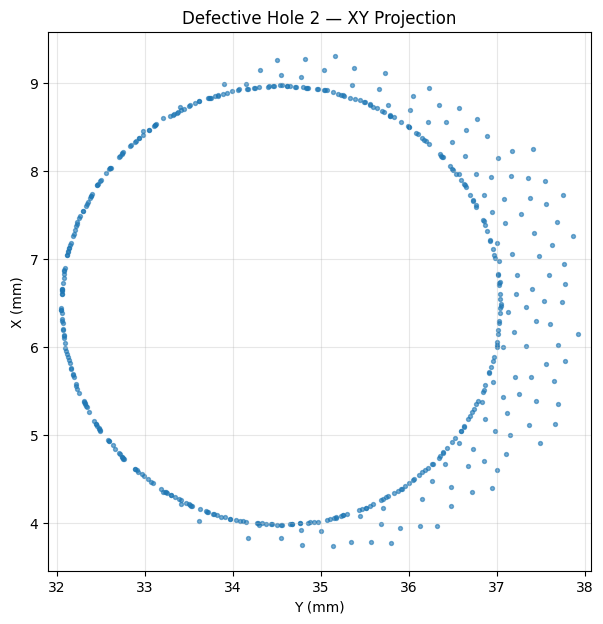

In [140]:
plt.figure(figsize=(7, 7))

plt.scatter(
    hole2_wall[:, 1],
    hole2_wall[:, 0],
    s=8,
    alpha=0.6
)

plt.xlabel("Y (mm)")
plt.ylabel("X (mm)")
plt.title("Defective Hole 2 — XY Projection")
plt.axis("equal")
plt.grid(alpha=0.3)
plt.show()

In [141]:
import features

hole2_restricted = features.measure_horizontal_hole(
    defective_points,
    approx_y=34.5,
    approx_x=6.5,
    z_min=2.0,
    z_max=3.2
)

print("Restricted Hole 2 measurement:")

for key, value in hole2_restricted.items():
    print(f"{key}: {value}")

Restricted Hole 2 measurement:
status: MEASURED
center_y_mm: 34.54400917045096
center_x_mm: 6.47429077431279
diameter_mm: 4.9838329632632545
fit_rmse_mm: 0.0037883066893578776
num_points: 256
angular_coverage_percent: 100.0
occupied_sectors: 36
total_sectors: 36
largest_empty_sector_gap_deg: 0.0


In [142]:
original = defective_holes["hole_2"]

print("Original fitted diameter:",
      original.get("diameter_mm"))

print("Restricted fitted diameter:",
      hole2_restricted.get("diameter_mm"))

print("\nOriginal RMSE:",
      original.get("fit_rmse_mm"))

print("Restricted RMSE:",
      hole2_restricted.get("fit_rmse_mm"))

print("\nOriginal points:",
      original.get("num_points"))

print("Restricted points:",
      hole2_restricted.get("num_points"))

Original fitted diameter: 5.152157204488877
Restricted fitted diameter: 4.9838329632632545

Original RMSE: 0.18171176852296841
Restricted RMSE: 0.0037883066893578776

Original points: 478
Restricted points: 256


In [143]:
from pathlib import Path

REAL_DATA_DIR = PROJECT_ROOT / "data/real/real3d_ad"
REAL_OUTPUT_DIR = PROJECT_ROOT / "outputs/real_validation"

REAL_DATA_DIR.mkdir(parents=True, exist_ok=True)
REAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Real dataset directory:", REAL_DATA_DIR)
print("Output directory:", REAL_OUTPUT_DIR)

Real dataset directory: /content/drive/MyDrive/Scan-to-CAD_System/data/real/real3d_ad
Output directory: /content/drive/MyDrive/Scan-to-CAD_System/outputs/real_validation


In [144]:
from pathlib import Path

DATASET_DIR = Path(
    "/content/drive/MyDrive/Scan-to-CAD_System/data/real/real3d_ad/candybar"
)

for path in sorted(DATASET_DIR.rglob("*.ply"))[:30]:
    print(path.relative_to(DATASET_DIR))

123_template.ply
137_good.ply
137_good_cut.ply
144_good.ply
144_good_cut.ply
151_good.ply
151_good_cut.ply
158_good.ply
158_good_cut.ply
165_good.ply
165_good_cut.ply
172_good.ply
172_good_cut.ply
179_good.ply
179_good_cut.ply
186_good.ply
186_good_cut.ply
200_good.ply
200_good_cut.ply
207_good.ply
207_good_cut.ply
228_good.ply
228_good_cut.ply
235_good.ply
235_good_cut.ply
242_good.ply
242_good_cut.ply
249_good.ply
249_good_cut.ply
256_good.ply


In [145]:
import open3d as o3d
import numpy as np

template_files = list(
    DATASET_DIR.rglob("123_template.ply")
)

good_files = list(
    DATASET_DIR.rglob("137_good.ply")
)

print("Templates found:", len(template_files))
print("Good scans found:", len(good_files))

assert len(template_files) == 1
assert len(good_files) == 1

template = o3d.io.read_point_cloud(
    str(template_files[0])
)

good_scan_real = o3d.io.read_point_cloud(
    str(good_files[0])
)

print("Template:", template)
print("Good scan:", good_scan_real)

Templates found: 1
Good scans found: 1
Template: PointCloud with 1001841 points.
Good scan: PointCloud with 89173 points.


In [146]:
for name, cloud in [
    ("Template", template),
    ("Good scan", good_scan_real)
]:
    points = np.asarray(cloud.points)

    bbox = cloud.get_axis_aligned_bounding_box()

    print(f"\n{name}")
    print("Points:", len(points))
    print("Minimum:", bbox.get_min_bound())
    print("Maximum:", bbox.get_max_bound())
    print("Bounding-box dimensions:", bbox.get_extent())
    print("Has colors:", cloud.has_colors())
    print("Has normals:", cloud.has_normals())


Template
Points: 1001841
Minimum: [ 93.31478119 -34.66423798 265.96331787]
Maximum: [111.87497711  -4.17709255 291.63021851]
Bounding-box dimensions: [18.56019592 30.48714542 25.66690063]
Has colors: False
Has normals: False

Good scan
Points: 89173
Minimum: [ 93.40093994 -34.67118835 266.06240845]
Maximum: [111.77262878  -4.10407877 291.66387939]
Bounding-box dimensions: [18.37168884 30.56710958 25.60147095]
Has colors: True
Has normals: False


In [147]:
import plotly.graph_objects as go

fig = go.Figure()

for name, cloud, color in [
    ("Template", template, "blue"),
    ("Good scan", good_scan_real, "orange")
]:
    points = np.asarray(cloud.points)

    # Limit display size for browser performance
    step = max(1, len(points) // 15000)
    points = points[::step]

    fig.add_trace(go.Scatter3d(
        x=points[:, 0],
        y=points[:, 1],
        z=points[:, 2],
        mode="markers",
        marker=dict(size=2, color=color),
        name=name
    ))

fig.update_layout(
    title="Real3D-AD — Template vs Normal Scan",
    scene=dict(
        xaxis_title="X",
        yaxis_title="Y",
        zaxis_title="Z",
        aspectmode="data"
    ),
    height=700
)

fig.show()

In [148]:
import open3d as o3d
import numpy as np

# Start with a voxel size of 0.15 dataset coordinate units
voxel_size = 0.15

template_down = template.voxel_down_sample(voxel_size)
good_down = good_scan_real.voxel_down_sample(voxel_size)

print("Original template:", len(template.points))
print("Downsampled template:", len(template_down.points))

print("Original good scan:", len(good_scan_real.points))
print("Downsampled good scan:", len(good_down.points))

Original template: 1001841
Downsampled template: 73363
Original good scan: 89173
Downsampled good scan: 35584


In [149]:
distances_before = np.asarray(
    good_down.compute_point_cloud_distance(
        template_down
    )
)

print("Before ICP registration")
print("Median distance:", np.median(distances_before))
print("Mean distance:", np.mean(distances_before))
print("95th percentile:", np.percentile(distances_before, 95))
print("Maximum distance:", np.max(distances_before))

Before ICP registration
Median distance: 0.07473298691918637
Mean distance: 0.07889858709429327
95th percentile: 0.14013830485053805
Maximum distance: 0.2728196994703476


In [150]:
initial_transform = np.eye(4)

icp_result = o3d.pipelines.registration.registration_icp(
    good_down,
    template_down,
    1.0,  # Maximum correspondence distance
    initial_transform,
    o3d.pipelines.registration.TransformationEstimationPointToPoint(),
    o3d.pipelines.registration.ICPConvergenceCriteria(
        max_iteration=100
    )
)

print("ICP fitness:", icp_result.fitness)
print("ICP RMSE:", icp_result.inlier_rmse)

print("\nEstimated transformation:")
print(icp_result.transformation)

ICP fitness: 1.0
ICP RMSE: 0.08045109114899025

Estimated transformation:
[[ 9.99985288e-01  3.20359040e-03  4.37734774e-03 -1.13028413e+00]
 [-3.20800091e-03  9.99994353e-01  1.00092682e-03  3.74811235e-02]
 [-4.37411646e-03 -1.01495463e-03  9.99989918e-01  4.59273597e-01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]


In [151]:
import copy

good_aligned = copy.deepcopy(good_down)

good_aligned.transform(
    icp_result.transformation
)

distances_after = np.asarray(
    good_aligned.compute_point_cloud_distance(
        template_down
    )
)

print("Before ICP:")
print("Median:", np.median(distances_before))
print("P95:", np.percentile(distances_before, 95))

print("\nAfter ICP:")
print("Median:", np.median(distances_after))
print("P95:", np.percentile(distances_after, 95))

Before ICP:
Median: 0.07473298691918637
P95: 0.14013830485053805

After ICP:
Median: 0.06762547150410833
P95: 0.13575233239828413


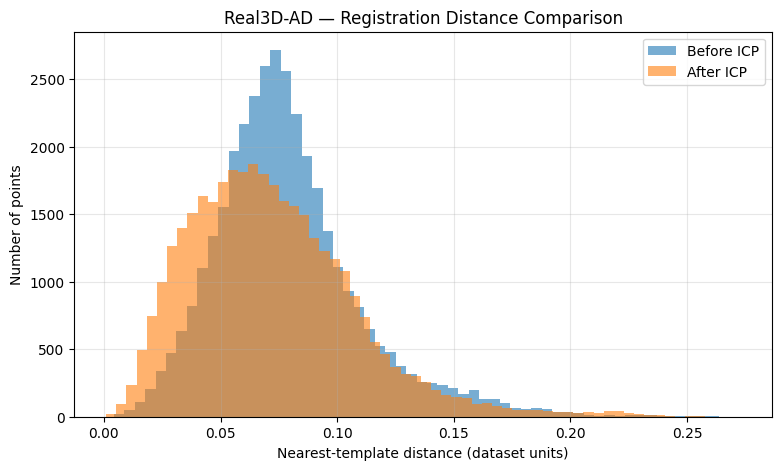

In [152]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    distances_before,
    bins=60,
    alpha=0.6,
    label="Before ICP"
)

plt.hist(
    distances_after,
    bins=60,
    alpha=0.6,
    label="After ICP"
)

plt.xlabel("Nearest-template distance (dataset units)")
plt.ylabel("Number of points")
plt.title("Real3D-AD — Registration Distance Comparison")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [153]:
import numpy as np

aligned_points = np.asarray(good_aligned.points)

assert len(aligned_points) == len(distances_after)

print("Aligned scan points:", len(aligned_points))
print("Distance values:", len(distances_after))

Aligned scan points: 35584
Distance values: 35584


In [154]:
import plotly.graph_objects as go

fig = go.Figure()

fig.add_trace(go.Scatter3d(
    x=aligned_points[:, 0],
    y=aligned_points[:, 1],
    z=aligned_points[:, 2],
    mode="markers",
    marker=dict(
        size=2,
        color=distances_after,
        colorscale="Turbo",
        cmin=0,
        cmax=0.25,
        colorbar=dict(
            title="Distance"
        )
    )
))

fig.update_layout(
    title="Real3D-AD — Normal Scan Deviation Heatmap",
    scene=dict(
        xaxis_title="X",
        yaxis_title="Y",
        zaxis_title="Z",
        aspectmode="data"
    ),
    width=900,
    height=700
)

fig.show()

In [155]:
import json

baseline = {
    "dataset": "Real3D-AD",
    "sample": "137_good.ply",
    "reference": "123_template.ply",
    "num_points": int(len(aligned_points)),
    "median_distance": float(np.median(distances_after)),
    "mean_distance": float(np.mean(distances_after)),
    "p95_distance": float(np.percentile(distances_after, 95)),
    "p99_distance": float(np.percentile(distances_after, 99)),
    "max_distance": float(np.max(distances_after)),
    "icp_fitness": float(icp_result.fitness),
    "icp_rmse": float(icp_result.inlier_rmse)
}

BASELINE_PATH = REAL_OUTPUT_DIR / "normal_baseline.json"

with open(BASELINE_PATH, "w") as f:
    json.dump(baseline, f, indent=2)

print(json.dumps(baseline, indent=2))

{
  "dataset": "Real3D-AD",
  "sample": "137_good.ply",
  "reference": "123_template.ply",
  "num_points": 35584,
  "median_distance": 0.06762547150410833,
  "mean_distance": 0.07204745496473836,
  "p95_distance": 0.13575233239828413,
  "p99_distance": 0.1901377278867118,
  "max_distance": 0.26218504227847567,
  "icp_fitness": 1.0,
  "icp_rmse": 0.08045109114899025
}


In [156]:
from pathlib import Path

all_ply = sorted(DATASET_DIR.rglob("*.ply"))

print("Total PLY files:", len(all_ply))

print("\nFiles not labeled 'good' or 'template':")

candidates = [
    path for path in all_ply
    if "good" not in path.name.lower()
    and "template" not in path.name.lower()
]

for path in candidates[:40]:
    print(path.relative_to(DATASET_DIR))

print("\nCandidate count:", len(candidates))

Total PLY files: 104

Files not labeled 'good' or 'template':
347_bulge.ply
347_bulge_cut.ply
354_bulge.ply
354_bulge_cut.ply
361_bulge.ply
361_bulge_cut.ply
368_bulge.ply
368_bulge_cut.ply
375_bulge.ply
375_bulge_cut.ply
382_bulge.ply
382_bulge_cut.ply
389_bulges.ply
389_bulges_cut.ply
396_bulge.ply
396_bulge_cut.ply
403_bulge.ply
403_bulge_cut.ply
410_bulge.ply
410_bulge_cut.ply
417_bulge.ply
417_bulge_cut.ply
424_bulge.ply
424_bulge_cut.ply
431_bulge.ply
431_bulge_cut.ply
438_bulge.ply
438_bulge_cut.ply
445_bulges.ply
445_bulges_cut.ply
452_bulges.ply
452_bulges_cut.ply
459_bulge.ply
459_bulge_cut.ply
466_bulges.ply
466_bulges_cut.ply
473_bulge.ply
473_bulge_cut.ply
480_sink.ply
480_sink_cut.ply

Candidate count: 50
